# 03 — Data Preparation

Notebook ini menjalankan tahap **Data Preparation** CRISP-DM untuk klasifikasi biner audio:

- `1 = berisik`
- `0 = non-berisik`

Tujuan tahap ini adalah menghasilkan dataset final yang dapat diaudit, bebas duplikat eksak, memiliki format audio seragam, dan memiliki 12 fitur yang dihitung dengan prosedur yang sama seperti deployment.

## Masukan

- `raw_audio/` (200 file MP3, read-only).
- `artifacts/02_data_understanding/manifest_raw.csv`.
- `artifacts/02_data_understanding/duplicate_groups.csv`.

## Keluaran utama

- `data_mp3/`: staging MP3 untuk file yang lolos seleksi.
- `data_final/`: WAV mono 16 kHz, tepat 480.000 sampel.
- `quarantine/03_data_preparation/`: salinan file yang dikarantina beserta catatan.
- `artifacts/features.csv`: 176 baris file final dan 12 fitur.
- `artifacts/selected_features.txt`: kandidat fitur eksploratif untuk Tahap 04.
- `artifacts/03_data_preparation/`: manifest, laporan, validasi, dan gambar.

## Batasan yang dipegang

1. `raw_audio/` tidak diubah atau dihapus.
2. Tidak ada label, NIM, atau take yang ditebak.
3. Duplikat dideteksi dari hash SHA-256, bukan dari kemiripan audio atau label.
4. Split berbasis NIM belum dibuat pada tahap ini.
5. Tidak ada training model, GridSearchCV, atau klaim model terbaik pada tahap ini.
6. Semua angka dan grafik berasal dari eksekusi data nyata.


In [1]:
import hashlib
import json
import math
import platform
import shutil
import warnings
from functools import reduce
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found.*")

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 120)

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["axes.titleweight"] = "bold"

RANDOM_STATE = 42

library_versions = pd.DataFrame(
    {
        "komponen": [
            "Python",
            "numpy",
            "pandas",
            "librosa",
            "soundfile",
            "scikit-learn",
            "matplotlib",
            "seaborn",
            "FFmpeg (PATH)",
        ],
        "versi": [
            platform.python_version(),
            np.__version__,
            pd.__version__,
            librosa.__version__,
            sf.__version__,
            __import__("sklearn").__version__,
            plt.matplotlib.__version__,
            sns.__version__,
            shutil.which("ffmpeg") or "tidak ditemukan",
        ],
    }
)

display(library_versions)


,komponen,versi
0,Python,3.11.9
1,numpy,2.4.6
2,pandas,2.3.3
3,librosa,0.11.0
4,soundfile,0.14.0
5,scikit-learn,1.8.0
6,matplotlib,3.11.0
7,seaborn,0.13.2
8,FFmpeg (PATH),tidak ditemukan


In [2]:
PROJECT_ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "raw_audio").is_dir() and (candidate / "artifacts").is_dir():
        PROJECT_ROOT = candidate.resolve()
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError("Folder proyek dengan raw_audio/ dan artifacts/ tidak ditemukan.")

RAW_DIR = PROJECT_ROOT / "raw_audio"
DATA_MP3_DIR = PROJECT_ROOT / "data_mp3"
DATA_FINAL_DIR = PROJECT_ROOT / "data_final"
QUARANTINE_DIR = PROJECT_ROOT / "quarantine" / "03_data_preparation"
ARTIFACT_ROOT = PROJECT_ROOT / "artifacts"
ARTIFACT_DIR = ARTIFACT_ROOT / "03_data_preparation"
FIGURE_DIR = ARTIFACT_DIR / "figures"
DU_ARTIFACT_DIR = ARTIFACT_ROOT / "02_data_understanding"

for directory in [
    DATA_MP3_DIR,
    DATA_FINAL_DIR,
    QUARANTINE_DIR,
    ARTIFACT_DIR,
    FIGURE_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

SR = 16000
TARGET_DURATION_S = 30.0
TARGET_SAMPLES = int(SR * TARGET_DURATION_S)
FRAME_LENGTH = 400
HOP_LENGTH = 160
N_FFT = 512
ROLLOFF_PERCENT = 0.85
TARGET_PEAK = 1.0
EPS = np.finfo(np.float64).eps
RANDOM_STATE = 42

LABEL_NAME_MAP = {0: "non-berisik", 1: "berisik"}
LABEL_ORDER = ["non-berisik", "berisik"]

FEATURE_COLUMNS = [
    "mse_energy",
    "rms_mean",
    "rms_std",
    "rms_max",
    "rms_min",
    "zcr_mean",
    "zcr_std",
    "spectral_centroid_mean",
    "spectral_centroid_std",
    "spectral_flatness_mean",
    "spectral_rolloff_mean",
    "spectral_bandwidth_mean",
]

SPECTRAL_FEATURES = [
    "spectral_centroid_mean",
    "spectral_centroid_std",
    "spectral_flatness_mean",
    "spectral_rolloff_mean",
    "spectral_bandwidth_mean",
]

IDENTITY_COLUMNS = ["file", "nim", "take", "label"]

PREPROCESSING_CONTRACT = {
    "sample_rate": SR,
    "channels": 1,
    "target_duration_seconds": TARGET_DURATION_S,
    "target_samples": TARGET_SAMPLES,
    "decode": "librosa.load(path, sr=16000, mono=True)",
    "longer_than_target": "center crop; start=(n_samples-target_samples)//2",
    "shorter_than_target": "center zero pad; left=pad//2, right=pad-left",
    "peak_normalization": "after crop/pad; y/max(abs(y))*1.0; error if max(abs(y))==0",
    "output_format": "WAV PCM_16, mono, 16000 Hz",
    "frame_length": FRAME_LENGTH,
    "hop_length": HOP_LENGTH,
    "n_fft": N_FFT,
    "window": "Hann simetris: 0.5 - 0.5*cos(2*pi*n/(L-1))",
    "rolloff_percent": ROLLOFF_PERCENT,
    "flatness_epsilon": float(EPS),
}

CONFIG = pd.DataFrame(
    {
        "parameter": [
            "project_root",
            "sample_rate",
            "target_duration_s",
            "target_samples",
            "frame_length",
            "hop_length",
            "n_fft",
            "rolloff_percent",
            "target_peak",
            "random_state",
        ],
        "nilai": [
            str(PROJECT_ROOT),
            SR,
            TARGET_DURATION_S,
            TARGET_SAMPLES,
            FRAME_LENGTH,
            HOP_LENGTH,
            N_FFT,
            ROLLOFF_PERCENT,
            TARGET_PEAK,
            RANDOM_STATE,
        ],
    }
)

display(CONFIG)
print(f"Artifact directory: {ARTIFACT_DIR}")


,parameter,nilai
0,project_root,C:\Users\ASUS\Downloads\dataset_30_detik
1,sample_rate,16000
2,target_duration_s,30.0
3,target_samples,480000
4,frame_length,400
5,hop_length,160
6,n_fft,512
7,rolloff_percent,0.85
8,target_peak,1.0
9,random_state,42


Artifact directory: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\03_data_preparation


## 1. Audit seleksi file dan duplikasi eksak

Section ini memeriksa ulang manifest Data Understanding sebelum file dipakai. Fokusnya bukan menghapus file, melainkan menetapkan status setiap file:

- `final`: file unik atau wakil eksplisit dari satu grup duplikat.
- `quarantine`: file duplikat yang tidak dipilih atau duplikat lintas label.

Aturan yang dipakai:

1. Kesamaan ditentukan dari **SHA-256 byte file**, bukan kemiripan sinyal atau label.
2. Duplikat **lintas label** tidak boleh menjadi satu pun kelas; semua anggotanya dikarantina.
3. Untuk duplikat **sama label**, dipilih tepat satu wakil per hash.
4. Pemilihan wakil memaksimalkan jumlah NIM yang mempertahankan kedua kelas, lalu menekan NIM satu kelas, baru memaksimalkan jumlah NIM yang masih terwakili.
5. `raw_audio/` tidak disentuh. File karantina akan **disalin** ke folder `quarantine/`.


In [3]:
manifest = pd.read_csv(DU_ARTIFACT_DIR / "manifest_raw.csv")
manifest["label"] = manifest["label"].astype(int)
manifest["take"] = manifest["take"].astype(int)
manifest["duplicate_group_id"] = manifest["duplicate_group_id"].fillna("").astype(str)
manifest["label_name"] = manifest["label"].map(LABEL_NAME_MAP)

required_columns = [
    "relative_path",
    "file",
    "nim",
    "take",
    "label",
    "sha256",
    "duplicate_group_id",
    "is_exact_duplicate",
    "duplicate_scope",
    "read_ok",
    "critical_failure",
]
missing_columns = [column for column in required_columns if column not in manifest.columns]
if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing_columns}")

checks = {
    "jumlah_file_200": len(manifest) == 200,
    "relatif_path_unik": manifest["relative_path"].is_unique,
    "identitas_lengkap": manifest[["nim", "take", "label"]].notna().all().all(),
    "label_valid_0_1": manifest["label"].isin([0, 1]).all(),
    "nama_file_terurai": manifest["name_parse_ok"].fillna(False).all(),
    "semua_file_terbaca": manifest["read_ok"].fillna(False).all(),
    "tidak_ada_kegagalan_kritis": not manifest["critical_failure"].fillna(True).any(),
    "tidak_ada_nan_inf": (
        manifest["nan_count"].fillna(1).eq(0) & manifest["inf_count"].fillna(1).eq(0)
    ).all(),
    "tidak_ada_sinyal_kosong": not manifest["all_zero"].fillna(True).any(),
    "sha256_lengkap": manifest["sha256"].notna().all(),
}
check_table = pd.DataFrame(
    {"pemeriksaan": list(checks), "lulus": list(checks.values())}
)
check_table["status"] = np.where(check_table["lulus"], "PASS", "FAIL")

if not all(checks.values()):
    raise ValueError("Manifest tidak lolos audit awal. Periksa tabel pemeriksaan.")

display(check_table)
display(
    manifest.groupby("label_name")
    .agg(
        n_files=("relative_path", "size"),
        n_nim=("nim", "nunique"),
        n_duplicate_files=("is_exact_duplicate", "sum"),
        n_peak_over_one=("peak_over_one", "sum"),
        n_low_level=("low_level", "sum"),
    )
    .reindex(LABEL_ORDER)
)

check_table.to_csv(ARTIFACT_DIR / "section1_input_checks.csv", index=False)


,pemeriksaan,lulus,status
0,jumlah_file_200,True,PASS
1,relatif_path_unik,True,PASS
2,identitas_lengkap,True,PASS
3,label_valid_0_1,True,PASS
4,nama_file_terurai,True,PASS
5,semua_file_terbaca,True,PASS
6,tidak_ada_kegagalan_kritis,True,PASS
7,tidak_ada_nan_inf,True,PASS
8,tidak_ada_sinyal_kosong,True,PASS
9,sha256_lengkap,True,PASS


,n_files,n_nim,n_duplicate_files,n_peak_over_one,n_low_level
label_name,,,,,
non-berisik,100,34,20,8,3
berisik,100,35,21,28,0


In [4]:
duplicate_groups = pd.read_csv(DU_ARTIFACT_DIR / "duplicate_groups.csv")
duplicate_groups["duplicate_group_id"] = duplicate_groups["duplicate_group_id"].astype(str)

manifest["sha256_recomputed"] = [
    hashlib.sha256((RAW_DIR / rel).read_bytes()).hexdigest()
    for rel in manifest["relative_path"]
]
if not (manifest["sha256"] == manifest["sha256_recomputed"]).all():
    raise ValueError("Hash SHA-256 tidak konsisten dengan manifest Data Understanding.")

hash_groups = (
    manifest.groupby("sha256")
    .agg(
        n_files=("relative_path", "size"),
        nims=("nim", lambda values: ", ".join(sorted(values.unique()))),
        n_nims=("nim", "nunique"),
        labels=("label", lambda values: ", ".join(str(int(v)) for v in sorted(values.unique()))),
        n_labels=("label", "nunique"),
        files=("relative_path", lambda values: " | ".join(sorted(values))),
    )
    .reset_index()
)
hash_groups = hash_groups.loc[hash_groups["n_files"] > 1].copy()
hash_groups["scope"] = np.where(
    hash_groups["n_labels"] > 1,
    "cross_label",
    np.where(hash_groups["n_nims"] > 1, "cross_nim", "within_nim"),
)

if len(hash_groups) != len(duplicate_groups):
    raise ValueError("Jumlah grup duplikat tidak konsisten dengan Tahap 02.")

expected_duplicate = manifest["sha256"].map(hash_groups.set_index("sha256")["n_files"]).fillna(1).gt(1)
if not (expected_duplicate == manifest["is_exact_duplicate"]).all():
    raise ValueError("Penandaan file duplikat tidak konsisten.")

scope_counts = (
    hash_groups["scope"]
    .value_counts()
    .rename_axis("scope")
    .reset_index(name="n_groups")
)
scope_counts["n_files"] = scope_counts["scope"].map(
    hash_groups.groupby("scope")["n_files"].sum()
).astype(int)

display(
    pd.DataFrame(
        {
            "pemeriksaan": [
                "total file",
                "hash unik",
                "file terlibat duplikat",
                "grup duplikat",
                "grup lintas label",
                "grup lintas NIM",
                "grup dalam NIM sama",
            ],
            "nilai": [
                len(manifest),
                manifest["sha256"].nunique(),
                int(manifest["is_exact_duplicate"].sum()),
                len(hash_groups),
                int(hash_groups["scope"].eq("cross_label").sum()),
                int(hash_groups["scope"].eq("cross_nim").sum()),
                int(hash_groups["scope"].eq("within_nim").sum()),
            ],
        }
    )
)
display(scope_counts)
display(
    hash_groups.loc[
        hash_groups["scope"] == "cross_label",
        ["files", "nims", "labels", "n_files"],
    ]
)

hash_groups.to_csv(ARTIFACT_DIR / "duplicate_audit.csv", index=False)


,pemeriksaan,nilai
0,total file,200
1,hash unik,177
2,file terlibat duplikat,41
3,grup duplikat,18
4,grup lintas label,1
5,grup lintas NIM,14
6,grup dalam NIM sama,3


,scope,n_groups,n_files
0,cross_nim,14,30
1,within_nim,3,9
2,cross_label,1,2


,files,nims,labels,n_files
103,berisik/24-034_berisik_1.mp3 | non-berisik/24-...,24-034,"0, 1",2


### 1.1 Aturan pemilihan wakil duplikat

Untuk setiap grup duplikat **sama label**, pilih tepat satu file. Semua file unik selalu dipertahankan. File dari grup **lintas label** tidak boleh menjadi wakil dan seluruh anggotanya dikarantina.

#### A. Rumus keputusan

Untuk himpunan file final \(F\), hitung:

\[
B(F)=\sum_{g=1}^{G}\mathbf{1}\left[\text{NIM }g\text{ memiliki kedua kelas}\right]
\]

\[
R(F)=\sum_{g=1}^{G}\mathbf{1}\left[\text{NIM }g\text{ masih terwakili}\right]
\]

\[
O(F)=\sum_{g=1}^{G}\mathbf{1}\left[\text{NIM }g\text{ hanya memiliki satu kelas}\right]
\]

Pilih kombinasi wakil dengan skor prioritas:

\[
Q(F)=1.000.000\,B(F)-10.000\,O(F)+100\,R(F)
\]

\[
F^{*}=\arg\max_{F} Q(F)
\]

Skor ini membuat jumlah NIM dengan kedua kelas menjadi prioritas utama. Jika masih seri, NIM satu kelas ditekan lebih dahulu, baru jumlah NIM yang terwakili dimaksimalkan. Urutan kandidat dibuat deterministik dari `duplicate_group_id` dan `relative_path`.

#### B. Ilustrasi manual

Misalkan ada dua NIM: A dan B. File unik awal hanya memberi A kelas berisik dan B kelas non-berisik. Ada dua grup duplikat:

- Grup 1 (berisik): kandidat dari A atau B.
- Grup 2 (non-berisik): kandidat dari A atau B.

| Pilihan | A berisik | A non | B berisik | B non | B | R | O |
|---|---:|---:|---:|---:|---:|---:|---:|
| Grup 1 → A, Grup 2 → A | 1 | 1 | 0 | 1 | 1 | 2 | 1 |
| Grup 1 → A, Grup 2 → B | 1 | 0 | 0 | 1 | 0 | 2 | 2 |

Pilihan pertama menang karena \(B=1\), meskipun sama-sama memiliki \(R=2\). Ini sesuai tujuan: mempertahankan kedua kelas pada sebanyak mungkin NIM.

#### C. Implementasi pada data nyata


In [5]:
def popcount64(values):
    values = np.asarray(values, dtype=np.uint64)
    if hasattr(np, "bitwise_count"):
        return np.bitwise_count(values).astype(np.int16)
    return (
        np.unpackbits(values.view(np.uint8), axis=-1, bitorder="little")
        .sum(axis=-1)
        .astype(np.int16)
    )


same_label_group_ids = sorted(
    manifest.loc[
        (manifest["duplicate_group_id"] != "")
        & (manifest["duplicate_scope"] != "cross_label"),
        "duplicate_group_id",
    ].unique()
)
group_choices = []
for group_id in same_label_group_ids:
    group = manifest.loc[
        manifest["duplicate_group_id"] == group_id
    ].sort_values("relative_path")
    if group["label"].nunique() != 1:
        raise ValueError(f"Grup same-label {group_id} memiliki lebih dari satu label.")
    group_choices.append(group)

nims = sorted(manifest["nim"].unique())
nim_bit = {nim: np.uint64(1) << np.uint64(index) for index, nim in enumerate(nims)}
unique_files = manifest.loc[~manifest["is_exact_duplicate"]].copy()

base_pos = np.uint64(0)
base_neg = np.uint64(0)
for row in unique_files.itertuples():
    if int(row.label) == 1:
        base_pos |= nim_bit[row.nim]
    else:
        base_neg |= nim_bit[row.nim]

choice_pos = []
choice_neg = []
for group in group_choices:
    bits = np.array([nim_bit[nim] for nim in group["nim"]], dtype=np.uint64)
    pos_bits = np.where(group["label"].to_numpy() == 1, bits, np.uint64(0))
    neg_bits = np.where(group["label"].to_numpy() == 0, bits, np.uint64(0))
    choice_pos.append(pos_bits)
    choice_neg.append(neg_bits)

dimensions = tuple(len(group) for group in group_choices)
grid = np.indices(dimensions).reshape(len(dimensions), -1).T.astype(np.int16)
n_combinations = len(grid)

pos_union = np.full(n_combinations, base_pos, dtype=np.uint64)
neg_union = np.full(n_combinations, base_neg, dtype=np.uint64)
for index in range(len(group_choices)):
    choice_index = grid[:, index]
    pos_union |= choice_pos[index][choice_index]
    neg_union |= choice_neg[index][choice_index]

both = popcount64(pos_union & neg_union)
one_class = popcount64(pos_union ^ neg_union)
represented = popcount64(pos_union | neg_union)
score = (
    both.astype(np.int64) * 1_000_000
    - one_class.astype(np.int64) * 10_000
    + represented.astype(np.int64) * 100
)
best_index = int(np.argmax(score))
best_choices = grid[best_index].astype(int)

selected_representatives = [
    group_choices[index].iloc[best_choices[index]]
    for index in range(len(group_choices))
]
selected_paths = {row["relative_path"] for row in selected_representatives}

selection = manifest.copy()
selection["selection_status"] = "quarantine"
selection["selection_reason"] = "duplikat_sama_label_bukan_wakil"
selection.loc[~selection["is_exact_duplicate"], "selection_status"] = "final"
selection.loc[~selection["is_exact_duplicate"], "selection_reason"] = "hash_unik"
selection.loc[
    selection["relative_path"].isin(selected_paths), "selection_status"
] = "final"
selection.loc[
    selection["relative_path"].isin(selected_paths), "selection_reason"
] = "wakil_grup_duplikat_sama_label"
selection.loc[
    selection["duplicate_scope"] == "cross_label", "selection_reason"
] = "duplikat_lintas_label"

final_manifest = selection.loc[selection["selection_status"] == "final"].copy()
final_manifest = final_manifest.sort_values(["nim", "label", "take"]).reset_index(drop=True)
quarantine_manifest = selection.loc[
    selection["selection_status"] == "quarantine"
].copy()

final_class_counts = final_manifest["label"].value_counts().sort_index().to_dict()
final_nims = sorted(final_manifest["nim"].unique())
nim_class_counts = final_manifest.groupby(["nim", "label"]).size().unstack(fill_value=0)
for label in [0, 1]:
    if label not in nim_class_counts.columns:
        nim_class_counts[label] = 0
nims_both = int(((nim_class_counts[0] > 0) & (nim_class_counts[1] > 0)).sum())
nims_one = sorted(
    nim_class_counts.index[
        (nim_class_counts[0] == 0) | (nim_class_counts[1] == 0)
    ].tolist()
)

if len(final_manifest) != 176:
    raise ValueError(f"Jumlah file final {len(final_manifest)}, bukan 176.")
if len(final_nims) != 34:
    raise ValueError(f"Jumlah NIM final {len(final_nims)}, bukan 34.")
if final_class_counts.get(1, 0) != 88 or final_class_counts.get(0, 0) != 88:
    raise ValueError(f"Distribusi kelas final tidak seimbang: {final_class_counts}.")
if nims_one:
    raise ValueError(f"Masih ada NIM satu kelas: {nims_one}.")
if not final_manifest["sha256"].is_unique:
    raise ValueError("File final masih memiliki hash duplikat.")

resolution_rows = []
for index, group in enumerate(group_choices):
    chosen = selected_representatives[index]
    resolution_rows.append(
        {
            "duplicate_group_id": group.iloc[0]["duplicate_group_id"],
            "label_name": LABEL_NAME_MAP[int(group.iloc[0]["label"])],
            "n_candidates": len(group),
            "candidates": " | ".join(group["relative_path"].tolist()),
            "selected": chosen["relative_path"],
            "selected_nim": chosen["nim"],
            "selected_take": int(chosen["take"]),
        }
    )
duplicate_resolution = pd.DataFrame(resolution_rows)

search_summary = {
    "n_same_label_groups": len(group_choices),
    "n_search_combinations": int(n_combinations),
    "best_both_class_nims": int(both[best_index]),
    "best_represented_nims": int(represented[best_index]),
    "best_one_class_nims": int(one_class[best_index]),
    "final_files": int(len(final_manifest)),
    "final_unique_hashes": int(final_manifest["sha256"].nunique()),
    "final_nims": int(len(final_nims)),
    "final_class_counts": {str(k): int(v) for k, v in final_class_counts.items()},
    "quarantined_files": int(len(quarantine_manifest)),
    "dropped_nims": sorted(set(manifest["nim"]) - set(final_nims)),
}

display(
    pd.DataFrame(
        {
            "metrik": [
                "kombinasi yang dievaluasi",
                "NIM dua kelas pada solusi terbaik",
                "NIM terwakili pada solusi terbaik",
                "NIM satu kelas pada solusi terbaik",
                "file final",
                "file karantina",
                "NIM final",
                "NIM hilang",
            ],
            "nilai": [
                n_combinations,
                search_summary["best_both_class_nims"],
                search_summary["best_represented_nims"],
                search_summary["best_one_class_nims"],
                len(final_manifest),
                len(quarantine_manifest),
                len(final_nims),
                ", ".join(search_summary["dropped_nims"]) or "-",
            ],
        }
    )
)
display(duplicate_resolution)
display(nim_class_counts.rename(columns={0: "non_berisik", 1: "berisik"}))

selection.to_csv(ARTIFACT_DIR / "selection_manifest_all.csv", index=False)
final_manifest.to_csv(ARTIFACT_DIR / "final_selection.csv", index=False)
quarantine_manifest.to_csv(ARTIFACT_DIR / "quarantine_manifest.csv", index=False)
duplicate_resolution.to_csv(ARTIFACT_DIR / "duplicate_resolution.csv", index=False)
with open(ARTIFACT_DIR / "duplicate_selection_summary.json", "w", encoding="utf-8") as handle:
    json.dump(search_summary, handle, ensure_ascii=False, indent=2)


,metrik,nilai
0,kombinasi yang dievaluasi,995328
1,NIM dua kelas pada solusi terbaik,34
2,NIM terwakili pada solusi terbaik,34
3,NIM satu kelas pada solusi terbaik,0
4,file final,176
5,file karantina,24
6,NIM final,34
7,NIM hilang,24-123


,duplicate_group_id,label_name,n_candidates,candidates,selected,selected_nim,selected_take
0,DUP01,berisik,2,berisik/24-003_berisik_1.mp3 | berisik/24-053_...,berisik/24-003_berisik_1.mp3,24-003,1
1,DUP02,berisik,2,berisik/24-003_berisik_2.mp3 | berisik/24-079_...,berisik/24-003_berisik_2.mp3,24-003,2
2,DUP03,berisik,3,berisik/24-003_berisik_3.mp3 | berisik/24-079_...,berisik/24-003_berisik_3.mp3,24-003,3
3,DUP05,berisik,2,berisik/24-071_berisik_1.mp3 | berisik/24-098_...,berisik/24-071_berisik_1.mp3,24-071,1
4,DUP06,berisik,2,berisik/24-071_berisik_2.mp3 | berisik/24-098_...,berisik/24-071_berisik_2.mp3,24-071,2
5,DUP07,berisik,2,berisik/24-071_berisik_3.mp3 | berisik/24-098_...,berisik/24-098_berisik_3.mp3,24-098,3
6,DUP08,berisik,2,berisik/24-115_berisik_3.mp3 | berisik/24-190_...,berisik/24-115_berisik_3.mp3,24-115,3
7,DUP09,berisik,2,berisik/24-123_berisik_1.mp3 | berisik/24-201_...,berisik/24-201_berisik_2.mp3,24-201,2
8,DUP10,berisik,3,berisik/24-157_berisik_1.mp3 | berisik/24-157_...,berisik/24-157_berisik_1.mp3,24-157,1
9,DUP11,non-berisik,2,non-berisik/24-003_non-berisik_2.mp3 | non-ber...,non-berisik/24-003_non-berisik_2.mp3,24-003,2


label,non_berisik,berisik
nim,,
24-003,2,3
24-006,3,3
24-007,3,3
24-026,3,3
24-027,3,3
24-031,2,3
24-034,2,2
24-053,2,1
24-068,3,3


In [6]:
quarantine_rows = []
for row in quarantine_manifest.sort_values("relative_path").itertuples():
    source = RAW_DIR / row.relative_path
    destination = QUARANTINE_DIR / row.relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)

    source_hash = hashlib.sha256(source.read_bytes()).hexdigest()
    if source_hash != row.sha256:
        raise ValueError(f"Hash sumber berubah sebelum karantina: {row.relative_path}")

    if destination.exists():
        destination_hash = hashlib.sha256(destination.read_bytes()).hexdigest()
        if destination_hash != source_hash:
            raise ValueError(f"File karantina lama berbeda: {destination}")
    else:
        shutil.copy2(source, destination)

    destination_hash = hashlib.sha256(destination.read_bytes()).hexdigest()
    if destination_hash != source_hash:
        raise ValueError(f"Salinan karantina tidak identik: {destination}")

    quarantine_rows.append(
        {
            "relative_path": row.relative_path,
            "file": row.file,
            "nim": row.nim,
            "take": int(row.take),
            "label": int(row.label),
            "label_name": row.label_name,
            "selection_reason": row.selection_reason,
            "duplicate_group_id": row.duplicate_group_id,
            "duplicate_scope": row.duplicate_scope,
            "sha256": row.sha256,
            "source_path": str(source),
            "quarantine_path": str(destination),
            "detected_stage": "03_data_preparation",
            "action": "copied_no_raw_deletion",
        }
    )

quarantine_log = pd.DataFrame(quarantine_rows)
quarantine_log.to_csv(QUARANTINE_DIR / "CATATAN_KARANTINA.csv", index=False)

with open(QUARANTINE_DIR / "README.md", "w", encoding="utf-8") as handle:
    handle.write(
        "# Karantina Tahap 03\n\n"
        "File di folder ini adalah **salinan** dari `raw_audio/`, bukan file asli yang dipindahkan.\n\n"
        "- Alasan utama: duplikat eksak lintas label atau duplikat same-label yang bukan wakil terpilih.\n"
        "- Rincian asal, hash SHA-256, grup duplikat, dan alasan ada di `CATATAN_KARANTINA.csv`.\n"
        "- File di sini tidak dipakai untuk `data_final/`, `features.csv`, atau modeling.\n"
    )

display(
    quarantine_log.groupby(["selection_reason", "label_name"])
    .size()
    .rename("n_files")
    .reset_index()
)
print(f"Total file dikarantina: {len(quarantine_log)}")
print(f"Catatan: {QUARANTINE_DIR / 'CATATAN_KARANTINA.csv'}")


,selection_reason,label_name,n_files
0,duplikat_lintas_label,berisik,1
1,duplikat_lintas_label,non-berisik,1
2,duplikat_sama_label_bukan_wakil,berisik,11
3,duplikat_sama_label_bukan_wakil,non-berisik,11


Total file dikarantina: 24
Catatan: C:\Users\ASUS\Downloads\dataset_30_detik\quarantine\03_data_preparation\CATATAN_KARANTINA.csv


In [7]:
class_selection_summary = (
    final_manifest.groupby("label_name")
    .agg(
        n_files=("relative_path", "size"),
        n_nim=("nim", "nunique"),
        n_take_1=("take", lambda values: int((values == 1).sum())),
        n_take_2=("take", lambda values: int((values == 2).sum())),
        n_take_3=("take", lambda values: int((values == 3).sum())),
    )
    .reindex(LABEL_ORDER)
    .reset_index()
)

nim_final_counts = (
    final_manifest.pivot_table(
        index="nim",
        columns="label_name",
        values="relative_path",
        aggfunc="count",
        fill_value=0,
    )
    .rename(columns={"berisik": "n_berisik", "non-berisik": "n_non_berisik"})
)
for column in ["n_berisik", "n_non_berisik"]:
    if column not in nim_final_counts.columns:
        nim_final_counts[column] = 0
nim_final_counts = nim_final_counts[["n_non_berisik", "n_berisik"]]
nim_final_counts["n_files"] = nim_final_counts.sum(axis=1)
nim_final_counts["kedua_kelas"] = (
    nim_final_counts["n_non_berisik"].gt(0) & nim_final_counts["n_berisik"].gt(0)
)
nim_final_counts = nim_final_counts.reset_index().sort_values("nim")

take_coverage = (
    final_manifest.pivot_table(
        index="label_name",
        columns="take",
        values="relative_path",
        aggfunc="count",
        fill_value=0,
    )
    .reindex(LABEL_ORDER)
    .reset_index()
)
for take in [1, 2, 3]:
    if take not in take_coverage.columns:
        take_coverage[take] = 0
take_coverage = take_coverage.rename(columns={1: "take_1", 2: "take_2", 3: "take_3"})

selection_summary = pd.DataFrame(
    {
        "metrik": [
            "file awal",
            "file final",
            "file karantina",
            "NIM awal",
            "NIM final",
            "NIM dua kelas",
            "NIM satu kelas",
            "file berisik final",
            "file non-berisik final",
            "grup duplikat same-label",
            "wakil duplikat dipilih",
        ],
        "nilai": [
            len(manifest),
            len(final_manifest),
            len(quarantine_manifest),
            manifest["nim"].nunique(),
            len(final_nims),
            nims_both,
            len(nims_one),
            int(final_manifest["label"].eq(1).sum()),
            int(final_manifest["label"].eq(0).sum()),
            len(group_choices),
            len(selected_representatives),
        ],
    }
)

display(class_selection_summary)
display(nim_final_counts)
display(take_coverage)
display(selection_summary)

class_selection_summary.to_csv(ARTIFACT_DIR / "class_selection_summary.csv", index=False)
nim_final_counts.to_csv(ARTIFACT_DIR / "nim_selection_summary.csv", index=False)
take_coverage.to_csv(ARTIFACT_DIR / "take_coverage.csv", index=False)
selection_summary.to_csv(ARTIFACT_DIR / "selection_summary.csv", index=False)

print("NIM yang tidak memiliki file final:", ", ".join(search_summary["dropped_nims"]) or "-")


,label_name,n_files,n_nim,n_take_1,n_take_2,n_take_3
0,non-berisik,88,34,29,30,29
1,berisik,88,34,29,29,30


label_name,nim,n_non_berisik,n_berisik,n_files,kedua_kelas
0,24-003,2,3,5,True
1,24-006,3,3,6,True
2,24-007,3,3,6,True
3,24-026,3,3,6,True
4,24-027,3,3,6,True
5,24-031,2,3,5,True
6,24-034,2,2,4,True
7,24-053,2,1,3,True
8,24-068,3,3,6,True
9,24-071,1,2,3,True


take,label_name,take_1,take_2,take_3
0,non-berisik,29,30,29
1,berisik,29,29,30


,metrik,nilai
0,file awal,200
1,file final,176
2,file karantina,24
3,NIM awal,35
4,NIM final,34
5,NIM dua kelas,34
6,NIM satu kelas,0
7,file berisik final,88
8,file non-berisik final,88
9,grup duplikat same-label,17


NIM yang tidak memiliki file final: 24-123


## 2. Penyamaan format dan kontrak preprocessing

Tujuan Section 2 adalah mengubah file final terpilih menjadi representasi seragam:

```text
raw_audio/ -> data_mp3/ -> data_final/
```

### 2.1 Keputusan staging MP3

Seluruh 200 file sumber sudah berformat MP3. Karena itu, `data_mp3/` dibuat sebagai **salinan byte-identik** dari file final terpilih, bukan transcode ulang MP3 ke MP3.

Alasannya:

1. Transcode ulang audio lossy menambah generasi kompresi kedua yang tidak diperlukan.
2. Dengan salinan byte-identik, sinyal yang didekode saat training sama dengan sinyal sumber yang akan dipakai saat deployment.
3. Keseragaman yang wajib untuk model tetap dilakukan di `data_final/`: mono, 16 kHz, tepat 480.000 sampel, dan peak normalization.

Jika kelak ada sumber non-MP3, file tersebut harus dikonversi ke MP3 sebelum masuk staging. Untuk dataset ini tidak ada sumber non-MP3.

### 2.2 Target sampel

\[
N_{\text{target}} = f_s \times 30 = 16.000 \times 30 = 480.000
\]

Setelah dekode ke mono 16 kHz, setiap sinyal harus memiliki panjang tepat \(N_{\text{target}}\). Kebijakan crop/pad harus deterministik dan sama persis dengan deployment.


In [8]:
if not (final_manifest["extension"] == ".mp3").all():
    raise ValueError("Ada file final yang bukan MP3; staging memerlukan aturan konversi tambahan.")

staging_rows = []
for row in final_manifest.sort_values("relative_path").itertuples():
    source = RAW_DIR / row.relative_path
    destination = DATA_MP3_DIR / row.relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)

    source_hash = hashlib.sha256(source.read_bytes()).hexdigest()
    if source_hash != row.sha256:
        raise ValueError(f"Hash sumber berubah: {row.relative_path}")

    if destination.exists():
        destination_hash = hashlib.sha256(destination.read_bytes()).hexdigest()
        if destination_hash != source_hash:
            raise ValueError(f"File staging lama berbeda: {destination}")
    else:
        shutil.copy2(source, destination)

    destination_hash = hashlib.sha256(destination.read_bytes()).hexdigest()
    if destination_hash != source_hash:
        raise ValueError(f"Salinan staging tidak identik: {destination}")

    staging_rows.append(
        {
            "source_relative_path": row.relative_path,
            "mp3_relative_path": row.relative_path,
            "file_mp3": row.file,
            "nim": row.nim,
            "take": int(row.take),
            "label": int(row.label),
            "label_name": row.label_name,
            "sha256": source_hash,
            "source_bytes": int(source.stat().st_size),
            "mp3_bytes": int(destination.stat().st_size),
            "staging_action": "copy_byte_identical_already_mp3",
        }
    )

staging_manifest = pd.DataFrame(staging_rows)
expected_mp3_paths = set(staging_manifest["mp3_relative_path"])
actual_mp3_paths = {
    path.relative_to(DATA_MP3_DIR).as_posix()
    for path in DATA_MP3_DIR.rglob("*")
    if path.is_file()
}
if actual_mp3_paths != expected_mp3_paths:
    extra = sorted(actual_mp3_paths - expected_mp3_paths)
    missing = sorted(expected_mp3_paths - actual_mp3_paths)
    raise ValueError(f"Struktur data_mp3 tidak sesuai. Ekstra: {extra}; hilang: {missing}")

display(staging_manifest.groupby("label_name").agg(n_files=("file_mp3", "size")).reindex(LABEL_ORDER))
print(f"File staging: {len(staging_manifest)}")
print(f"Total ukuran MP3 staging: {staging_manifest['mp3_bytes'].sum() / 1024**2:.2f} MB")

staging_manifest.to_csv(ARTIFACT_DIR / "staging_manifest.csv", index=False)


,n_files
label_name,
non-berisik,88
berisik,88


File staging: 176
Total ukuran MP3 staging: 79.43 MB


### 2.3 Crop dan pad ke 30 detik

Semua file mentah berdurasi 30 detik, sehingga pada dataset ini seharusnya tidak ada crop atau pad. Meskipun demikian, kontraknya tetap harus ada agar deployment menangani durasi lain secara identik.

Urutan operasi: **decode -> mono 16 kHz -> crop/pad -> peak normalization -> tulis WAV**.

#### A. Rumus crop

Jika \(N > N_{\text{target}}\), ambil potongan di tengah:

\[
s=\left\lfloor\frac{N-N_{\text{target}}}{2}\right\rfloor
\]

\[
y_{\text{crop}}[n]=y[s+n],\qquad n=0,\ldots,N_{\text{target}}-1
\]

#### B. Ilustrasi crop

Misalkan \(y=[10,11,12,13,14,15]\) dan \(N_{\text{target}}=4\).

\[
s=\lfloor(6-4)/2\rfloor=1
\]

Hasil: \([11,12,13,14]\). Sampel awal dan akhir dibuang seimbang.

#### A. Rumus pad

Jika \(N < N_{\text{target}}\):

\[
P=N_{\text{target}}-N,\qquad L_{\text{pad}}=\left\lfloor\frac{P}{2}\right\rfloor,\qquad R_{\text{pad}}=P-L_{\text{pad}}
\]

\[
y_{\text{pad}}=[\underbrace{0,\ldots,0}_{L_{\text{pad}}},y_0,\ldots,y_{N-1},\underbrace{0,\ldots,0}_{R_{\text{pad}}}]
\]

Jika \(P\) ganjil, satu sampel nol tambahan diletakkan di kanan.

#### B. Ilustrasi pad

Misalkan \(y=[10,11,12]\), \(N_{\text{target}}=5\), maka \(P=2\), \(L_{\text{pad}}=1\), \(R_{\text{pad}}=1\):

\[
y_{\text{pad}}=[0,10,11,12,0]
\]

#### C. Implementasi pada data nyata


In [9]:
def fit_duration_to_target(y, target_samples=TARGET_SAMPLES):
    y = np.asarray(y)
    original_samples = int(len(y))
    crop_start = 0
    pad_left = 0
    pad_right = 0

    if original_samples > target_samples:
        action = "crop"
        crop_start = (original_samples - target_samples) // 2
        y_out = y[crop_start : crop_start + target_samples].copy()
    elif original_samples < target_samples:
        action = "pad"
        total_pad = target_samples - original_samples
        pad_left = total_pad // 2
        pad_right = total_pad - pad_left
        y_out = np.pad(y, (pad_left, pad_right), mode="constant", constant_values=0.0)
    else:
        action = "none"
        y_out = y.copy()

    if len(y_out) != target_samples:
        raise ValueError("Panjang sinyal tidak sama dengan target sampel.")

    return y_out, {
        "original_samples_16k": original_samples,
        "original_duration_16k_s": original_samples / SR,
        "action": action,
        "crop_start": int(crop_start),
        "pad_left": int(pad_left),
        "pad_right": int(pad_right),
        "final_samples": int(len(y_out)),
    }


staging_meta = staging_manifest.merge(
    manifest[["relative_path", "samplerate", "channels"]],
    left_on="source_relative_path",
    right_on="relative_path",
    how="left",
    validate="one_to_one",
)
preview_rows = (
    staging_meta.sort_values("source_relative_path")
    .groupby("samplerate", sort=True)
    .head(1)
)

duration_preview = []
for row in preview_rows.itertuples():
    y_preview, preview_sr = librosa.load(
        DATA_MP3_DIR / row.mp3_relative_path, sr=SR, mono=True
    )
    if preview_sr != SR:
        raise ValueError("librosa tidak mengembalikan sample rate yang diminta.")
    _, preview_meta = fit_duration_to_target(y_preview)
    duration_preview.append(
        {
            "file": row.file_mp3,
            "source_samplerate": int(row.samplerate),
            "source_channels": int(row.channels),
            "decoded_samples_16k": len(y_preview),
            "decoded_duration_16k_s": len(y_preview) / SR,
            "action": preview_meta["action"],
            "final_samples": preview_meta["final_samples"],
        }
    )

duration_preview = pd.DataFrame(duration_preview)
display(duration_preview)


,file,source_samplerate,source_channels,decoded_samples_16k,decoded_duration_16k_s,action,final_samples
0,24-003_berisik_1.mp3,44100,2,480000,30.0,none,480000
1,24-003_berisik_2.mp3,48000,2,480000,30.0,none,480000
2,24-100_berisik_1.mp3,16000,1,480000,30.0,none,480000


### 2.4 Peak normalization

Peak normalization menyamakan skala amplitudo tanpa mengubah bentuk gelombang, durasi, atau kecepatan.

#### A. Rumus

\[
p=\max_{n}|y[n]|
\]

\[
y_{\text{norm}}[n]=
\begin{cases}
y[n]/p, & p>0\\
\text{error}, & p=0
\end{cases}
\]

Target peak adalah \(1.0\). Normalisasi dilakukan **setelah** crop/pad dan sebelum WAV ditulis. Jika \(p=0\), sinyal kosong tidak boleh dinormalisasi diam-diam; file harus ditolak.

#### B. Ilustrasi manual

Misalkan \(y=[0{,}2,\;-0{,}4,\;0{,}1]\).

\[
p=\max(0{,}2;0{,}4;0{,}1)=0{,}4
\]

\[
y_{\text{norm}}=[0{,}5,\;-1{,}0,\;0{,}25]
\]

Jika seluruh sampel nol, \(p=0\), maka operasi harus menghasilkan error, bukan pembagian dengan nol.

#### C. Implementasi pada data nyata


In [10]:
def peak_normalize(y, target_peak=TARGET_PEAK):
    y = np.asarray(y)
    if y.size == 0:
        raise ValueError("Sinyal kosong tidak dapat dinormalisasi.")
    if not np.isfinite(y).all():
        raise ValueError("Sinyal mengandung NaN atau Inf.")
    peak_before = float(np.max(np.abs(y)))
    if peak_before <= 0:
        raise ValueError("Peak sinyal nol; file harus ditolak, bukan dinormalisasi.")
    y_norm = (y / peak_before * target_peak).astype(np.float32)
    peak_after = float(np.max(np.abs(y_norm)))
    return y_norm, {
        "peak_before": peak_before,
        "peak_after": peak_after,
        "target_peak": float(target_peak),
    }


example_row = staging_manifest.sort_values("mp3_relative_path").iloc[0]
example_y, example_sr = librosa.load(
    DATA_MP3_DIR / example_row["mp3_relative_path"], sr=SR, mono=True
)
example_fitted, example_fit_meta = fit_duration_to_target(example_y)
example_normalized, example_peak_meta = peak_normalize(example_fitted)

display(
    pd.DataFrame(
        {
            "pemeriksaan": [
                "file contoh",
                "sample rate",
                "sampel setelah fit durasi",
                "peak sebelum normalisasi",
                "peak setelah normalisasi",
                "target peak",
                "NaN",
                "Inf",
            ],
            "nilai": [
                example_row["file_mp3"],
                example_sr,
                len(example_fitted),
                example_peak_meta["peak_before"],
                example_peak_meta["peak_after"],
                example_peak_meta["target_peak"],
                int(np.isnan(example_normalized).sum()),
                int(np.isinf(example_normalized).sum()),
            ],
        }
    )
)


,pemeriksaan,nilai
0,file contoh,24-003_berisik_1.mp3
1,sample rate,16000
2,sampel setelah fit durasi,480000
3,peak sebelum normalisasi,0.416976
4,peak setelah normalisasi,1.0
5,target peak,1.0
6,NaN,0
7,Inf,0


In [11]:
conversion_meta = staging_meta.merge(
    manifest[["relative_path", "duration_decoded_s"]].rename(
        columns={"relative_path": "source_relative_path"}
    ),
    on="source_relative_path",
    how="left",
    validate="one_to_one",
)

transformation_rows = []
for row in conversion_meta.sort_values("mp3_relative_path").itertuples():
    mp3_path = DATA_MP3_DIR / row.mp3_relative_path
    final_relative_path = Path(row.mp3_relative_path).with_suffix(".wav").as_posix()
    final_path = DATA_FINAL_DIR / final_relative_path
    final_path.parent.mkdir(parents=True, exist_ok=True)

    y, loaded_sr = librosa.load(mp3_path, sr=SR, mono=True)
    if loaded_sr != SR:
        raise ValueError(f"Sample rate hasil dekode bukan 16 kHz: {mp3_path}")

    y_fit, fit_meta = fit_duration_to_target(y)
    y_norm, peak_meta = peak_normalize(y_fit)
    sf.write(final_path, y_norm, SR, subtype="PCM_16")

    info = sf.info(final_path)
    y_written, written_sr = sf.read(final_path, dtype="float32")
    if written_sr != SR:
        raise ValueError(f"Sample rate WAV salah: {final_path}")
    if info.frames != TARGET_SAMPLES:
        raise ValueError(f"Jumlah sampel WAV salah: {final_path}")
    if info.channels != 1:
        raise ValueError(f"Jumlah kanal WAV salah: {final_path}")
    if info.subtype != "PCM_16":
        raise ValueError(f"Subtype WAV salah: {final_path}")

    transformation_rows.append(
        {
            "file": Path(final_relative_path).name,
            "nim": row.nim,
            "take": int(row.take),
            "label": int(row.label),
            "label_name": row.label_name,
            "source_relative_path": row.source_relative_path,
            "mp3_relative_path": row.mp3_relative_path,
            "final_relative_path": final_relative_path,
            "source_sha256": row.sha256,
            "mp3_sha256": hashlib.sha256(mp3_path.read_bytes()).hexdigest(),
            "final_sha256": hashlib.sha256(final_path.read_bytes()).hexdigest(),
            "source_samplerate": int(row.samplerate),
            "source_channels": int(row.channels),
            "source_duration_s": float(row.duration_decoded_s),
            "loaded_sr": int(loaded_sr),
            "decoded_samples_16k": int(len(y)),
            "decoded_duration_16k_s": float(len(y) / SR),
            "duration_action": fit_meta["action"],
            "crop_start": fit_meta["crop_start"],
            "pad_left": fit_meta["pad_left"],
            "pad_right": fit_meta["pad_right"],
            "final_samples": int(info.frames),
            "final_format": info.format,
            "final_subtype": info.subtype,
            "final_channels": int(info.channels),
            "final_samplerate": int(info.samplerate),
            "peak_before_norm": peak_meta["peak_before"],
            "peak_after_norm": peak_meta["peak_after"],
            "peak_pcm16": float(np.max(np.abs(y_written))),
            "target_peak": peak_meta["target_peak"],
            "normalization_applied": True,
            "status": "ok",
        }
    )

transformation_manifest = pd.DataFrame(transformation_rows)
expected_wav_paths = set(transformation_manifest["final_relative_path"])
actual_wav_paths = {
    path.relative_to(DATA_FINAL_DIR).as_posix()
    for path in DATA_FINAL_DIR.rglob("*")
    if path.is_file()
}
if actual_wav_paths != expected_wav_paths:
    extra = sorted(actual_wav_paths - expected_wav_paths)
    missing = sorted(expected_wav_paths - actual_wav_paths)
    raise ValueError(f"Struktur data_final tidak sesuai. Ekstra: {extra}; hilang: {missing}")

if len(transformation_manifest) != 176:
    raise ValueError("Jumlah file hasil konversi bukan 176.")
if not transformation_manifest["final_sha256"].is_unique:
    raise ValueError("Ada WAV final dengan hash identik.")

with open(ARTIFACT_DIR / "preprocessing_contract.json", "w", encoding="utf-8") as handle:
    json.dump(PREPROCESSING_CONTRACT, handle, ensure_ascii=False, indent=2)

display(
    transformation_manifest.groupby(["duration_action", "label_name"])
    .agg(
        n_files=("file", "size"),
        min_samples=("final_samples", "min"),
        max_samples=("final_samples", "max"),
        min_peak=("peak_pcm16", "min"),
        max_peak=("peak_pcm16", "max"),
    )
    .reset_index()
)
print(f"File WAV final: {len(transformation_manifest)}")
print(f"Total ukuran WAV: {sum((DATA_FINAL_DIR / p).stat().st_size for p in expected_wav_paths) / 1024**2:.2f} MB")

transformation_manifest.to_csv(ARTIFACT_DIR / "transformation_manifest.csv", index=False)


,duration_action,label_name,n_files,min_samples,max_samples,min_peak,max_peak
0,none,berisik,88,480000,480000,0.999969,1.0
1,none,non-berisik,88,480000,480000,0.999969,1.0


File WAV final: 176
Total ukuran WAV: 161.14 MB


In [12]:
file_checks = []
for row in transformation_manifest.itertuples():
    final_path = DATA_FINAL_DIR / row.final_relative_path
    mp3_path = DATA_MP3_DIR / row.mp3_relative_path
    y, sr = sf.read(final_path, dtype="float32")
    info = sf.info(final_path)

    checks = {
        "file_ada": final_path.is_file(),
        "mp3_sama_dengan_raw": row.source_sha256 == row.mp3_sha256,
        "mp3_ada": mp3_path.is_file(),
        "sample_rate_16k": sr == SR,
        "mono": y.ndim == 1 and info.channels == 1,
        "pcm16": info.subtype == "PCM_16",
        "tepat_480000": len(y) == TARGET_SAMPLES,
        "durasi_30_detik": abs(len(y) / SR - TARGET_DURATION_S) < 1e-9,
        "tidak_nan": int(np.isnan(y).sum()) == 0,
        "tidak_inf": int(np.isinf(y).sum()) == 0,
        "tidak_kosong": bool(np.any(y != 0)),
        "peak_maksimal_1": float(np.max(np.abs(y))) <= 1.00001,
    }
    file_checks.append(
        {
            "file": row.file,
            "final_relative_path": row.final_relative_path,
            **checks,
            "peak": float(np.max(np.abs(y))),
            "rms": float(np.sqrt(np.mean(y.astype(np.float64) ** 2))),
        }
    )

final_audio_validation = pd.DataFrame(file_checks)
failed_rows = final_audio_validation.loc[
    ~final_audio_validation.drop(columns=["file", "final_relative_path", "peak", "rms"]).all(axis=1)
]
if len(failed_rows):
    raise ValueError(f"Ada file final yang gagal validasi: {len(failed_rows)}")

transition_summary = (
    transformation_manifest.groupby(["duration_action", "label_name"])
    .agg(n_files=("file", "size"), min_peak=("peak_pcm16", "min"), max_peak=("peak_pcm16", "max"))
    .reset_index()
)

display(transition_summary)
display(
    final_audio_validation[["file", "peak", "rms"]]
    .describe(percentiles=[0.5])
    .T.reset_index()
    .rename(columns={"index": "metrik"})
)

final_audio_summary = {
    "n_files": int(len(final_audio_validation)),
    "n_unique_final_hashes": int(transformation_manifest["final_sha256"].nunique()),
    "sample_rate": int(SR),
    "channels": 1,
    "samples_per_file": int(TARGET_SAMPLES),
    "duration_s": float(TARGET_DURATION_S),
    "duration_actions": {
        str(k): int(v)
        for k, v in transformation_manifest["duration_action"].value_counts().items()
    },
    "all_checks_passed": bool(len(failed_rows) == 0),
}
with open(ARTIFACT_DIR / "final_audio_summary.json", "w", encoding="utf-8") as handle:
    json.dump(final_audio_summary, handle, ensure_ascii=False, indent=2)

final_audio_validation.to_csv(ARTIFACT_DIR / "final_audio_validation.csv", index=False)
print("Validasi audio final: PASS")


,duration_action,label_name,n_files,min_peak,max_peak
0,none,berisik,88,0.999969,1.0
1,none,non-berisik,88,0.999969,1.0


,metrik,count,mean,std,min,50%,max
0,peak,176.0,0.999981,0.000015,0.999969,0.999969,1.000000
1,rms,176.0,0.104724,0.050949,0.021961,0.092844,0.259299


Validasi audio final: PASS


## 3. Framing dan ekstraksi 12 fitur

Setiap file final sudah berupa mono 16 kHz dengan 480.000 sampel. Fitur dihitung dengan pengaturan yang sama untuk semua file:

| Komponen | Nilai |
|---|---|
| Sample rate | 16.000 Hz |
| Panjang frame | 400 sampel = 25 ms |
| Hop | 160 sampel = 10 ms |
| Overlap | 240 sampel = 60% |
| FFT | 512 titik (zero-padding dari 400) |
| Window | Hann simetris |
| Resolusi frekuensi | 31,25 Hz |
| Jumlah bin rFFT | 257 (0–8.000 Hz) |

Tidak ada `center=True`. Frame hanya diambil jika seluruh 400 sampel tersedia. Konsekuensinya, 80 sampel terakhir dari 480.000 sampel tidak masuk frame terakhir, tetapi tetap dipakai untuk `mse_energy` yang dihitung dari seluruh sinyal.


### 3.1 Framing

#### A. Rumus jumlah frame

Untuk sinyal \(y\) dengan panjang \(N\), frame length \(L\), dan hop \(H\), tanpa penambahan frame di awal atau akhir:

\[
M=1+\left\lfloor\frac{N-L}{H}\right\rfloor,\qquad N\ge L
\]

Frame ke-\(m\) adalah:

\[
\mathbf{x}_m=[y[mH],y[mH+1],\ldots,y[mH+L-1]]
\]

Dengan \(N=480.000\), \(L=400\), dan \(H=160\):

\[
M=1+\left\lfloor\frac{480.000-400}{160}\right\rfloor
=1+2.997=2.998
\]

Frame terakhir mulai pada sampel \(2.997\times160=479.520\) dan berakhir pada sampel \(479.919\). Sampel \(479.920\)–\(479.999\) tidak masuk frame, tetapi tetap dipakai untuk `mse_energy`.

#### B. Ilustrasi manual

Misalkan \(y=[0,1,2,3,4,5,6,7,8,9]\), \(L=4\), \(H=2\).

\[
M=1+\lfloor(10-4)/2\rfloor=1+3=4
\]

Frame yang terbentuk:

- \(m=0\): \([0,1,2,3]\)
- \(m=1\): \([2,3,4,5]\)
- \(m=2\): \([4,5,6,7]\)
- \(m=3\): \([6,7,8,9]\)

#### C. Implementasi pada data nyata


In [13]:
def frame_signal(y, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH):
    y = np.asarray(y)
    if len(y) < frame_length:
        raise ValueError("Sinyal lebih pendek dari satu frame.")
    frames = np.lib.stride_tricks.sliding_window_view(y, frame_length)[::hop_length]
    return frames


example_row = transformation_manifest.sort_values("final_relative_path").iloc[0]
example_path = DATA_FINAL_DIR / example_row["final_relative_path"]
example_y, example_sr = sf.read(example_path, dtype="float32")

if len(example_y) != TARGET_SAMPLES or example_sr != SR:
    raise ValueError("File contoh tidak sesuai kontrak 16 kHz / 480.000 sampel.")

example_frames = frame_signal(example_y)
expected_frames = 1 + (len(example_y) - FRAME_LENGTH) // HOP_LENGTH

if example_frames.shape != (expected_frames, FRAME_LENGTH):
    raise ValueError("Bentuk frame tidak sesuai rumus jumlah frame.")

last_covered_sample = (example_frames.shape[0] - 1) * HOP_LENGTH + FRAME_LENGTH - 1
uncovered_samples = len(example_y) - last_covered_sample - 1

display(
    pd.DataFrame(
        {
            "besaran": [
                "file contoh",
                "panjang sinyal N",
                "frame length L",
                "hop H",
                "jumlah frame aktual",
                "jumlah frame rumus",
                "bentuk matriks frame",
                "sampel terakhir yang tercakup",
                "sampel tidak tercakup",
            ],
            "nilai": [
                example_row["file"],
                len(example_y),
                FRAME_LENGTH,
                HOP_LENGTH,
                example_frames.shape[0],
                expected_frames,
                str(example_frames.shape),
                last_covered_sample,
                uncovered_samples,
            ],
        }
    )
)


,besaran,nilai
0,file contoh,24-003_berisik_1.wav
1,panjang sinyal N,480000
2,frame length L,400
3,hop H,160
4,jumlah frame aktual,2998
5,jumlah frame rumus,2998
6,bentuk matriks frame,"(2998, 400)"
7,sampel terakhir yang tercakup,479919
8,sampel tidak tercakup,80


### 3.2 Overlap antar-frame

#### A. Rumus

\[
O=L-H
\]

\[
r_{\text{overlap}}=\frac{L-H}{L}
\]

Dengan \(L=400\) dan \(H=160\):

\[
O=240,\qquad r_{\text{overlap}}=\frac{240}{400}=0{,}60
\]

Overlap 240 sampel setara 15 ms. Hop 160 sampel setara 10 ms.

#### B. Ilustrasi manual

Misalkan \(L=4\), \(H=2\). Maka \(O=2\) dan \(r=2/4=0{,}5\).

Frame 0: \([0,1,2,3]\). Frame 1: \([2,3,4,5]\). Dua sampel, yaitu \(2\) dan \(3\), dipakai dua kali.

#### C. Implementasi pada data nyata


In [14]:
overlap_samples = FRAME_LENGTH - HOP_LENGTH
overlap_ratio = overlap_samples / FRAME_LENGTH
overlap_ms = overlap_samples / SR * 1000
hop_ms = HOP_LENGTH / SR * 1000

actual_overlap_matches = np.array_equal(
    example_frames[0, HOP_LENGTH:],
    example_frames[1, :FRAME_LENGTH - HOP_LENGTH],
)
if not actual_overlap_matches:
    raise ValueError("Frame berurutan tidak memiliki overlap yang diharapkan.")

display(
    pd.DataFrame(
        {
            "besaran": [
                "frame length",
                "hop",
                "overlap sampel",
                "overlap rasio",
                "overlap ms",
                "hop ms",
                "overlap frame 0 dan 1 identik",
            ],
            "nilai": [
                FRAME_LENGTH,
                HOP_LENGTH,
                overlap_samples,
                overlap_ratio,
                overlap_ms,
                hop_ms,
                actual_overlap_matches,
            ],
        }
    )
)


,besaran,nilai
0,frame length,400
1,hop,160
2,overlap sampel,240
3,overlap rasio,0.6
4,overlap ms,15.0
5,hop ms,10.0
6,overlap frame 0 dan 1 identik,True


### 3.3 Window Hann simetris

#### A. Rumus

Untuk \(n=0,1,\ldots,L-1\):

\[
w[n]=0{,}5-0{,}5\cos\left(\frac{2\pi n}{L-1}\right)
\]

Window ini simetris dan bernilai nol di kedua ujung. Tujuannya mengurangi kebocoran spektral akibat pemotongan frame.

#### B. Ilustrasi manual

Untuk \(L=4\):

\[
w[0]=0,\quad w[1]=0{,}75,\quad w[2]=0{,}75,\quad w[3]=0
\]

Jadi \(w=[0,\;0{,}75,\;0{,}75,\;0]\).

#### C. Implementasi pada data nyata


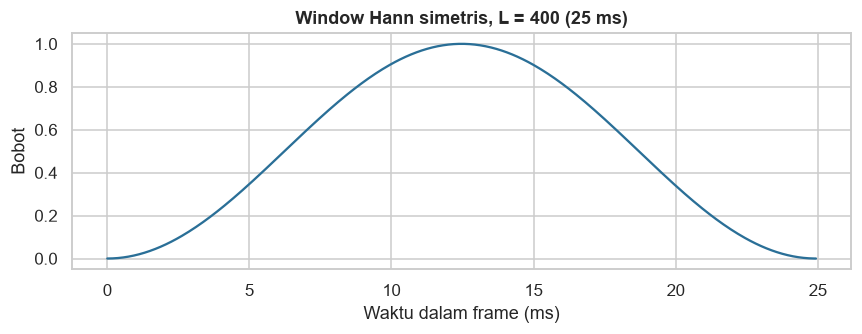

,besaran,nilai
0,panjang window,400
1,nilai awal,0.0
2,nilai akhir,0.0
3,nilai maksimum,0.999985
4,simetris,True
5,identik dengan np.hanning,True


In [15]:
hann_window = 0.5 - 0.5 * np.cos(
    2 * np.pi * np.arange(FRAME_LENGTH) / (FRAME_LENGTH - 1)
)
if not np.allclose(hann_window, np.hanning(FRAME_LENGTH), atol=1e-15):
    raise ValueError("Window Hann tidak sesuai definisi simetris.")
if not (hann_window[0] == 0 and hann_window[-1] == 0):
    raise ValueError("Window Hann harus nol di kedua ujung.")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(np.arange(FRAME_LENGTH) / SR * 1000, hann_window, color="#2a6f97")
ax.set_title("Window Hann simetris, L = 400 (25 ms)")
ax.set_xlabel("Waktu dalam frame (ms)")
ax.set_ylabel("Bobot")
ax.set_ylim(-0.05, 1.05)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "hann_window.png", bbox_inches="tight")
plt.show()

display(
    pd.DataFrame(
        {
            "besaran": [
                "panjang window",
                "nilai awal",
                "nilai akhir",
                "nilai maksimum",
                "simetris",
                "identik dengan np.hanning",
            ],
            "nilai": [
                FRAME_LENGTH,
                hann_window[0],
                hann_window[-1],
                hann_window.max(),
                np.allclose(hann_window, hann_window[::-1]),
                np.allclose(hann_window, np.hanning(FRAME_LENGTH)),
            ],
        }
    )
)


### 3.4 Windowing

#### A. Rumus

Untuk setiap frame \(m\) dan indeks \(n=0,\ldots,L-1\):

\[
x_w[m,n]=x[m,n]\,w[n]
\]

Window yang sama dipakai untuk semua frame dan semua file.

#### B. Ilustrasi manual

Dengan \(x=[1,2,3,4]\) dan \(w=[0,\;0{,}75,\;0{,}75,\;0]\):

\[
x_w=[1\cdot0,\;2\cdot0{,}75,\;3\cdot0{,}75,\;4\cdot0]
=[0,\;1{,}5,\;2{,}25,\;0]
\]

#### C. Implementasi pada data nyata


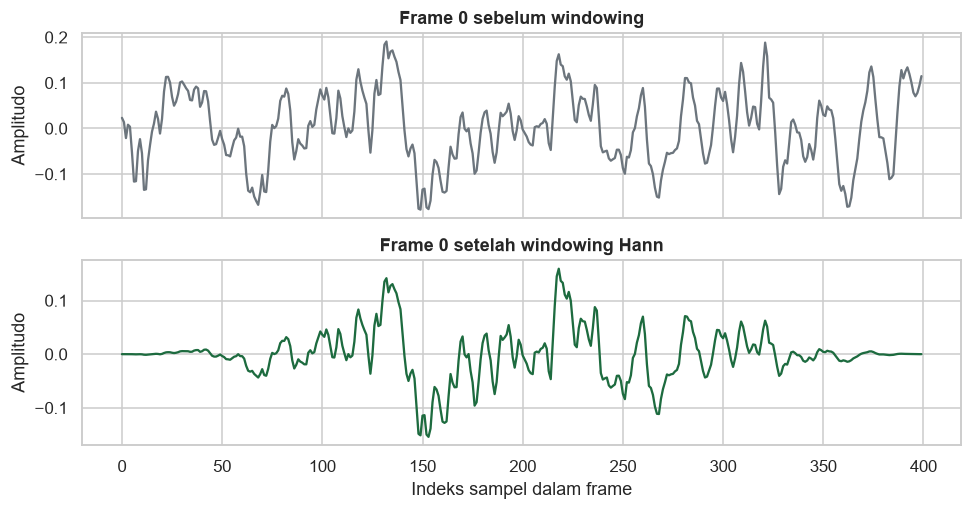

,besaran,nilai
0,bentuk frame sebelum,"(2998, 400)"
1,bentuk frame sesudah,"(2998, 400)"
2,sampel awal frame 0,0.0
3,sampel akhir frame 0,0.0
4,energi frame 0 sebelum,2.487724
5,energi frame 0 sesudah,0.895091


In [16]:
example_windowed = example_frames * hann_window[None, :]

if example_windowed.shape != example_frames.shape:
    raise ValueError("Windowing tidak boleh mengubah bentuk frame.")
if not np.allclose(example_windowed[:, [0, -1]], 0):
    raise ValueError("Sampel tepi frame setelah windowing harus nol.")

fig, axes = plt.subplots(2, 1, figsize=(9, 4.8), sharex=True)
axes[0].plot(example_frames[0], color="#6c757d")
axes[0].set_title("Frame 0 sebelum windowing")
axes[0].set_ylabel("Amplitudo")
axes[1].plot(example_windowed[0], color="#1d6b3f")
axes[1].set_title("Frame 0 setelah windowing Hann")
axes[1].set_xlabel("Indeks sampel dalam frame")
axes[1].set_ylabel("Amplitudo")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "windowing_example.png", bbox_inches="tight")
plt.show()

display(
    pd.DataFrame(
        {
            "besaran": [
                "bentuk frame sebelum",
                "bentuk frame sesudah",
                "sampel awal frame 0",
                "sampel akhir frame 0",
                "energi frame 0 sebelum",
                "energi frame 0 sesudah",
            ],
            "nilai": [
                str(example_frames.shape),
                str(example_windowed.shape),
                float(example_windowed[0, 0]),
                float(example_windowed[0, -1]),
                float(np.sum(example_frames[0] ** 2)),
                float(np.sum(example_windowed[0] ** 2)),
            ],
        }
    )
)


### 3.5 Short-Time Fourier Transform dan spektrum daya

#### A. Rumus

Frame yang sudah diberi window dan di-zero-pad dari 400 ke 512 sampel dihitung dengan rFFT:

\[
S[m,k]=\sum_{n=0}^{L-1}x_w[m,n]\,
e^{-j2\pi kn/N_{\text{FFT}}},
\qquad k=0,\ldots,N_{\text{FFT}}/2
\]

\[
P[m,k]=|S[m,k]|^2
\]

Dengan \(N_{\text{FFT}}=512\), jumlah bin rFFT adalah 257 (0 sampai 8.000 Hz). Zero-padding 112 sampel tidak menambah informasi, tetapi memperhalus grid frekuensi dan menghasilkan 512 titik FFT.

#### B. Ilustrasi manual

Ambil \(x=[1,0,-1,0]\), window persegi, dan \(N_{\text{FFT}}=4\). Maka:

- \(S[0]=1+0-1+0=0\)
- \(S[1]=1-(-1)=2\)
- \(S[2]=1-1=0\)
- \(S[3]=1-(-1)=2\)

Jadi \(P=[0,4,0,4]\). Bin dengan daya terbesar adalah bin 1 dan 3.

#### C. Implementasi pada data nyata


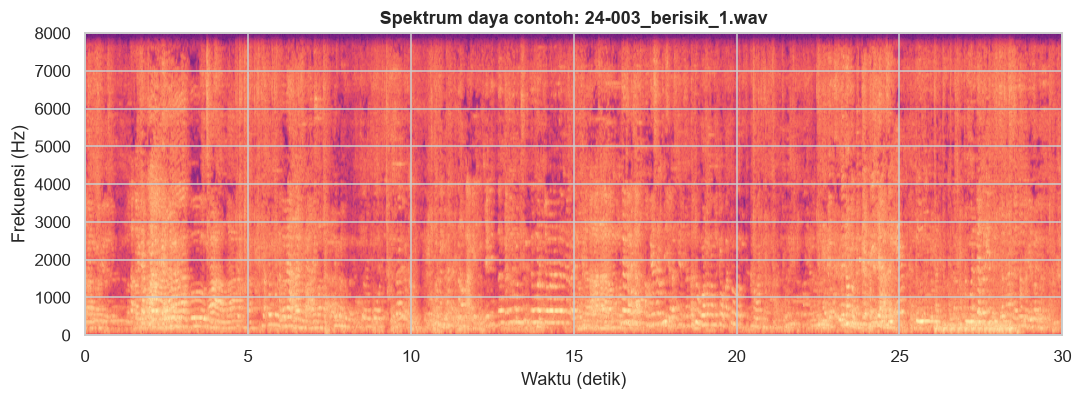

,besaran,nilai
0,bentuk frame,"(2998, 400)"
1,bentuk STFT manual,"(2998, 257)"
2,bentuk FFT penuh (pemeriksaan),"(2998, 512)"
3,jumlah bin frekuensi,257
4,resolusi frekuensi (Hz),31.25
5,selisih maksimum daya rFFT vs FFT penuh,0.0


In [17]:
example_S = np.fft.rfft(example_windowed, n=N_FFT, axis=1)
example_P = np.abs(example_S) ** 2
FREQS = np.fft.rfftfreq(N_FFT, d=1 / SR)

S_full_fft = np.fft.fft(example_windowed, n=N_FFT, axis=1)
P_full_fft = np.abs(S_full_fft[:, : N_FFT // 2 + 1]) ** 2
fft_rfft_max_abs_diff = float(np.max(np.abs(P_full_fft - example_P)))

if example_P.shape != (example_frames.shape[0], N_FFT // 2 + 1):
    raise ValueError("Bentuk spektrum daya tidak sesuai.")
if fft_rfft_max_abs_diff > 1e-6:
    raise ValueError("rFFT dan FFT penuh berbeda terlalu besar.")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.imshow(
    10 * np.log10(example_P.T + EPS),
    origin="lower",
    aspect="auto",
    extent=[0, TARGET_DURATION_S, 0, SR / 2],
    cmap="magma",
)
ax.set_title(f"Spektrum daya contoh: {example_row['file']}")
ax.set_xlabel("Waktu (detik)")
ax.set_ylabel("Frekuensi (Hz)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "power_spectrum_example.png", bbox_inches="tight")
plt.show()

display(
    pd.DataFrame(
        {
            "besaran": [
                "bentuk frame",
                "bentuk STFT manual",
                "bentuk FFT penuh (pemeriksaan)",
                "jumlah bin frekuensi",
                "resolusi frekuensi (Hz)",
                "selisih maksimum daya rFFT vs FFT penuh",
            ],
            "nilai": [
                str(example_windowed.shape),
                str(example_S.shape),
                str(S_full_fft.shape),
                len(FREQS),
                FREQS[1] - FREQS[0],
                fft_rfft_max_abs_diff,
            ],
        }
    )
)


### 3.6 MSE energy

#### A. Rumus

\[
\text{MSE} = \frac{1}{N}\sum_{n=0}^{N-1}y[n]^2
\]

Ini adalah rata-rata kuadrat amplitudo untuk **seluruh sinyal 480.000 sampel**, bukan total energi dan bukan rata-rata dari fitur frame.

#### B. Ilustrasi manual

Misalkan \(y=[0{,}1,\;-0{,}2,\;0{,}3,\;-0{,}4]\).

\[
\text{MSE}=\frac{0{,}01+0{,}04+0{,}09+0{,}16}{4}=0{,}075
\]

#### C. Implementasi pada data nyata


In [18]:
features_base = transformation_manifest[["file", "nim", "take", "label"]].copy()
features_mse = features_base.copy()
mse_values = []

for row in transformation_manifest.itertuples():
    y, sr = sf.read(DATA_FINAL_DIR / row.final_relative_path, dtype="float32")
    if sr != SR or len(y) != TARGET_SAMPLES:
        raise ValueError(f"File tidak sesuai kontrak: {row.file}")
    mse_values.append(float(np.mean(y.astype(np.float64) ** 2)))

features_mse["mse_energy"] = mse_values
if not np.isfinite(features_mse["mse_energy"]).all():
    raise ValueError("MSE mengandung NaN atau Inf.")

display(
    features_mse.groupby("label")
    .agg(
        n=("mse_energy", "size"),
        mean=("mse_energy", "mean"),
        median=("mse_energy", "median"),
        min=("mse_energy", "min"),
        max=("mse_energy", "max"),
    )
    .rename(index=LABEL_NAME_MAP)
)

features_mse.to_csv(ARTIFACT_DIR / "features_mse.csv", index=False)


,n,mean,median,min,max
label,,,,,
non-berisik,88,0.007457,0.004784,0.000482,0.038643
berisik,88,0.019639,0.014998,0.000898,0.067236


### 3.7 RMS per frame

#### A. Rumus

Untuk setiap frame \(m\):

\[
\text{RMS}_m=\sqrt{\frac{1}{L}\sum_{n=0}^{L-1}x[m,n]^2}
\]

Fitur agregat:

\[
\text{rms\_mean}=\frac{1}{M}\sum_{m=0}^{M-1}\text{RMS}_m
\]

`rms_std` adalah simpangan baku populasi dari \(M\) nilai RMS frame, `rms_max` nilai maksimum, dan `rms_min` nilai minimum.

#### B. Ilustrasi manual

Misalkan satu frame \(x=[0{,}5,\;-0{,}5,\;1{,}0,\;-1{,}0]\).

\[
\text{RMS}=\sqrt{\frac{0{,}25+0{,}25+1+1}{4}}
=\sqrt{0{,}625}\approx0{,}7906
\]

#### C. Implementasi pada data nyata


In [19]:
rms_rows = []
for row in transformation_manifest.itertuples():
    y, sr = sf.read(DATA_FINAL_DIR / row.final_relative_path, dtype="float32")
    frames = frame_signal(y).astype(np.float64)
    rms_frames = np.sqrt(np.mean(frames**2, axis=1))
    rms_rows.append(
        {
            "file": row.file,
            "rms_mean": float(np.mean(rms_frames)),
            "rms_std": float(np.std(rms_frames, ddof=0)),
            "rms_max": float(np.max(rms_frames)),
            "rms_min": float(np.min(rms_frames)),
        }
    )

features_rms = pd.DataFrame(rms_rows)
if len(features_rms) != 176 or not np.isfinite(features_rms.iloc[:, 1:]).all().all():
    raise ValueError("Fitur RMS tidak valid.")
features_rms = features_base.merge(features_rms, on="file", validate="one_to_one")

display(
    features_rms.groupby("label")[
        ["rms_mean", "rms_std", "rms_max", "rms_min"]
    ].median().rename(index=LABEL_NAME_MAP)
)
features_rms.to_csv(ARTIFACT_DIR / "features_rms.csv", index=False)


,rms_mean,rms_std,rms_max,rms_min
label,,,,
non-berisik,0.050656,0.044971,0.391700,0.000457
berisik,0.100758,0.067212,0.457375,0.000529


### 3.8 Zero-crossing rate

#### A. Rumus

Untuk setiap frame \(m\):

\[
\text{ZCR}_m=\frac{1}{L-1}\sum_{n=0}^{L-2}
\mathbf{1}\left[x[m,n]\cdot x[m,n+1]<0\right]
\]

Fitur:

\[
\text{zcr\_mean}=\frac{1}{M}\sum_m \text{ZCR}_m,\qquad
\text{zcr\_std}=\text{std populasi}(\text{ZCR}_m)
\]

Produk negatif berarti pasangan sampel berpindah tanda. Konvensi ini dicatat karena librosa dapat menghitung zero crossing dengan definisi tepi yang sedikit berbeda.

#### B. Ilustrasi manual

Untuk \(x=[1,-1,1,1]\):

\[
x_nx_{n+1}=[-1,-1,1]
\]

Ada dua perkalian negatif dari tiga pasangan:

\[
\text{ZCR}=\frac{2}{3}\approx0{,}6667
\]

#### C. Implementasi pada data nyata


In [20]:
zcr_rows = []
for row in transformation_manifest.itertuples():
    y, sr = sf.read(DATA_FINAL_DIR / row.final_relative_path, dtype="float32")
    frames = frame_signal(y).astype(np.float64)
    zcr_frames = np.mean((frames[:, :-1] * frames[:, 1:]) < 0, axis=1)
    zcr_rows.append(
        {
            "file": row.file,
            "zcr_mean": float(np.mean(zcr_frames)),
            "zcr_std": float(np.std(zcr_frames, ddof=0)),
        }
    )

features_zcr = pd.DataFrame(zcr_rows)
if len(features_zcr) != 176 or not np.isfinite(features_zcr.iloc[:, 1:]).all().all():
    raise ValueError("Fitur ZCR tidak valid.")
features_zcr = features_base.merge(features_zcr, on="file", validate="one_to_one")

display(
    features_zcr.groupby("label")[["zcr_mean", "zcr_std"]]
    .median()
    .rename(index=LABEL_NAME_MAP)
)
features_zcr.to_csv(ARTIFACT_DIR / "features_zcr.csv", index=False)


,zcr_mean,zcr_std
label,,
non-berisik,0.091896,0.044711
berisik,0.113027,0.044521


### 3.9 Spectral centroid

#### A. Rumus

Untuk setiap frame dengan spektrum daya \(P[m,k]\) dan frekuensi \(f_k\):

\[
C_m=\frac{\sum_{k=0}^{K-1} f_k P[m,k]}
{\sum_{k=0}^{K-1} P[m,k]}
\]

Fitur:

\[
\text{centroid\_mean}=\frac{1}{M}\sum_m C_m,\qquad
\text{centroid\_std}=\text{std populasi}(C_m)
\]

Jika jumlah daya satu frame nol, centroid frame tersebut ditetapkan 0 dan dicatat sebagai frame kosong.

#### B. Ilustrasi manual

Misalkan \(f=[0,1000,2000]\) Hz dan \(P=[1,3,0]\).

\[
C=\frac{0\cdot1+1000\cdot3+2000\cdot0}{1+3+0}
=\frac{3000}{4}=750\text{ Hz}
\]

#### C. Implementasi pada data nyata


In [21]:
centroid_rows = []
for row in transformation_manifest.itertuples():
    y, sr = sf.read(DATA_FINAL_DIR / row.final_relative_path, dtype="float32")
    frames = frame_signal(y).astype(np.float64)
    P = np.abs(np.fft.rfft(frames * hann_window[None, :], n=N_FFT, axis=1)) ** 2
    power_sum = P.sum(axis=1)
    centroids = np.divide(
        P @ FREQS,
        power_sum,
        out=np.zeros_like(power_sum),
        where=power_sum > 0,
    )
    centroid_rows.append(
        {
            "file": row.file,
            "spectral_centroid_mean": float(np.mean(centroids)),
            "spectral_centroid_std": float(np.std(centroids, ddof=0)),
            "empty_power_frames": int((power_sum == 0).sum()),
        }
    )

features_centroid = pd.DataFrame(centroid_rows)
if len(features_centroid) != 176 or not np.isfinite(
    features_centroid[["spectral_centroid_mean", "spectral_centroid_std"]]
).all().all():
    raise ValueError("Fitur spectral centroid tidak valid.")
silent_frame_audit = features_centroid[["file", "empty_power_frames"]].copy()
features_centroid = features_base.merge(
    features_centroid.drop(columns=["empty_power_frames"]), on="file", validate="one_to_one"
)

display(
    features_centroid.groupby("label")[
        ["spectral_centroid_mean", "spectral_centroid_std"]
    ].median().rename(index=LABEL_NAME_MAP)
)
print(
    "Frame dengan daya nol:",
    int(silent_frame_audit["empty_power_frames"].sum()),
    "pada",
    int((silent_frame_audit["empty_power_frames"] > 0).sum()),
    "file; centroid frame tersebut ditetapkan 0.",
)
features_centroid.to_csv(ARTIFACT_DIR / "features_centroid.csv", index=False)
silent_frame_audit.to_csv(ARTIFACT_DIR / "silent_frames.csv", index=False)


,spectral_centroid_mean,spectral_centroid_std
label,,
non-berisik,594.657221,320.582941
berisik,705.555963,323.249867


Frame dengan daya nol: 1677 pada 52 file; centroid frame tersebut ditetapkan 0.


### 3.10 Spectral flatness

#### A. Rumus

Untuk setiap frame:

\[
\text{GM}_m=\exp\left(\frac{1}{K}\sum_{k=0}^{K-1}\log(P[m,k]+\epsilon)\right)
\]

\[
\text{AM}_m=\frac{1}{K}\sum_{k=0}^{K-1}(P[m,k]+\epsilon)
\]

\[
\text{flatness}_m=\frac{\text{GM}_m}{\text{AM}_m}
\]

Nilai mendekati 1 berarti spektrum mirip noise/merata; nilai mendekati 0 berarti energi terkonsentrasi pada sebagian bin. \(\epsilon\) adalah epsilon kecil agar `log` tetap terdefinisi. Untuk frame dengan daya total nol (hening digital), flatness ditetapkan 0 karena tidak ada konten spektral yang dapat diukur. Fitur akhir adalah rata-rata flatness seluruh frame.

#### B. Ilustrasi manual

Misalkan \(P=[4,1,1,0{,}25]\) (tanpa epsilon untuk ilustrasi).

\[
\text{GM}=(4\cdot1\cdot1\cdot0{,}25)^{1/4}=1
\]

\[
\text{AM}=\frac{4+1+1+0{,}25}{4}=1{,}5625
\]

\[
\text{flatness}=\frac{1}{1{,}5625}=0{,}64
\]

#### C. Implementasi pada data nyata


In [22]:
flatness_rows = []
for row in transformation_manifest.itertuples():
    y, sr = sf.read(DATA_FINAL_DIR / row.final_relative_path, dtype="float32")
    frames = frame_signal(y).astype(np.float64)
    P = np.abs(np.fft.rfft(frames * hann_window[None, :], n=N_FFT, axis=1)) ** 2
    P_eps = P + EPS
    flatness_frames = np.exp(np.mean(np.log(P_eps), axis=1)) / np.mean(P_eps, axis=1)
    flatness_frames[P.sum(axis=1) == 0] = 0
    flatness_rows.append(
        {
            "file": row.file,
            "spectral_flatness_mean": float(np.mean(flatness_frames)),
        }
    )

features_flatness = pd.DataFrame(flatness_rows)
if len(features_flatness) != 176 or not np.isfinite(
    features_flatness["spectral_flatness_mean"]
).all():
    raise ValueError("Fitur spectral flatness tidak valid.")
if not features_flatness["spectral_flatness_mean"].between(0, 1).all():
    raise ValueError("Spectral flatness berada di luar rentang [0, 1].")
features_flatness = features_base.merge(
    features_flatness, on="file", validate="one_to_one"
)

display(
    features_flatness.groupby("label")[["spectral_flatness_mean"]]
    .median()
    .rename(index=LABEL_NAME_MAP)
)
features_flatness.to_csv(ARTIFACT_DIR / "features_flatness.csv", index=False)


,spectral_flatness_mean
label,
non-berisik,0.013866
berisik,0.012310


### 3.11 Spectral rolloff 85%

#### A. Rumus

Untuk setiap frame, hitung kumulatif daya:

\[
\Gamma[m,k]=\sum_{j=0}^{k}P[m,j]
\]

Cari indeks terkecil \(k^*\) sehingga:

\[
\Gamma[m,k^*]\ge 0{,}85\sum_{j=0}^{K-1}P[m,j]
\]

\[
R_m=f_{k^*}
\]

Fitur `spectral_rolloff_mean` adalah rata-rata \(R_m\) seluruh frame. Jika total daya frame nol, rolloff frame tersebut ditetapkan 0.

#### B. Ilustrasi manual

Misalkan \(f=[0,1000,2000,3000]\) Hz dan \(P=[1,1,1,1]\).

Total daya \(=4\), ambang \(=0{,}85\times4=3{,}4\).

Kumulatif: \(1,2,3,4\). Nilai pertama yang \(\ge3{,}4\) adalah 4 pada indeks 3, sehingga:

\[
R=3000\text{ Hz}
\]

#### C. Implementasi pada data nyata


In [23]:
rolloff_rows = []
for row in transformation_manifest.itertuples():
    y, sr = sf.read(DATA_FINAL_DIR / row.final_relative_path, dtype="float32")
    frames = frame_signal(y).astype(np.float64)
    P = np.abs(np.fft.rfft(frames * hann_window[None, :], n=N_FFT, axis=1)) ** 2
    cumulative = np.cumsum(P, axis=1)
    total_power = cumulative[:, -1]
    thresholds = ROLLOFF_PERCENT * total_power
    rolloff_indices = np.argmax(cumulative >= thresholds[:, None], axis=1)
    rolloff_frames = FREQS[rolloff_indices].copy()
    rolloff_frames[total_power == 0] = 0
    rolloff_rows.append(
        {
            "file": row.file,
            "spectral_rolloff_mean": float(np.mean(rolloff_frames)),
        }
    )

features_rolloff = pd.DataFrame(rolloff_rows)
if len(features_rolloff) != 176 or not np.isfinite(
    features_rolloff["spectral_rolloff_mean"]
).all():
    raise ValueError("Fitur spectral rolloff tidak valid.")
if not features_rolloff["spectral_rolloff_mean"].between(0, SR / 2).all():
    raise ValueError("Spectral rolloff berada di luar rentang frekuensi.")
features_rolloff = features_base.merge(
    features_rolloff, on="file", validate="one_to_one"
)

display(
    features_rolloff.groupby("label")[["spectral_rolloff_mean"]]
    .median()
    .rename(index=LABEL_NAME_MAP)
)
features_rolloff.to_csv(ARTIFACT_DIR / "features_rolloff.csv", index=False)


,spectral_rolloff_mean
label,
non-berisik,895.425075
berisik,1091.112825


### 3.12 Spectral bandwidth

#### A. Rumus

Untuk setiap frame, dengan centroid \(C_m\):

\[
B_m=\sqrt{
\frac{\sum_{k=0}^{K-1}P[m,k](f_k-C_m)^2}
{\sum_{k=0}^{K-1}P[m,k]}
}
\]

Fitur `spectral_bandwidth_mean` adalah rata-rata \(B_m\) seluruh frame. Ini adalah simpangan baku spektrum berbobot daya, bukan bandwidth fisik codec.

#### B. Ilustrasi manual

Misalkan \(f=[0,1000,2000]\) Hz dan \(P=[1,0,1]\).

\[
C=\frac{0+0+2000}{2}=1000\text{ Hz}
\]

\[
B=\sqrt{\frac{1(0-1000)^2+0+1(2000-1000)^2}{2}}
=\sqrt{1.000.000}=1000\text{ Hz}
\]

#### C. Implementasi pada data nyata


In [24]:
bandwidth_rows = []
for row in transformation_manifest.itertuples():
    y, sr = sf.read(DATA_FINAL_DIR / row.final_relative_path, dtype="float32")
    frames = frame_signal(y).astype(np.float64)
    P = np.abs(np.fft.rfft(frames * hann_window[None, :], n=N_FFT, axis=1)) ** 2
    power_sum = P.sum(axis=1)
    centroids = np.divide(
        P @ FREQS,
        power_sum,
        out=np.zeros_like(power_sum),
        where=power_sum > 0,
    )
    variance = np.divide(
        (P * (FREQS[None, :] - centroids[:, None]) ** 2).sum(axis=1),
        power_sum,
        out=np.zeros_like(power_sum),
        where=power_sum > 0,
    )
    bandwidth_frames = np.sqrt(np.maximum(variance, 0))
    bandwidth_rows.append(
        {
            "file": row.file,
            "spectral_bandwidth_mean": float(np.mean(bandwidth_frames)),
        }
    )

features_bandwidth = pd.DataFrame(bandwidth_rows)
if len(features_bandwidth) != 176 or not np.isfinite(
    features_bandwidth["spectral_bandwidth_mean"]
).all():
    raise ValueError("Fitur spectral bandwidth tidak valid.")
if not (features_bandwidth["spectral_bandwidth_mean"] >= 0).all():
    raise ValueError("Spectral bandwidth bernilai negatif.")
features_bandwidth = features_base.merge(
    features_bandwidth, on="file", validate="one_to_one"
)

display(
    features_bandwidth.groupby("label")[["spectral_bandwidth_mean"]]
    .median()
    .rename(index=LABEL_NAME_MAP)
)
features_bandwidth.to_csv(ARTIFACT_DIR / "features_bandwidth.csv", index=False)


,spectral_bandwidth_mean
label,
non-berisik,557.281721
berisik,654.622295


### 3.13 Penggabungan fitur

Semua fitur dihitung dari file final yang sama dan diidentifikasi dengan `file`. Penggabungan dilakukan dengan validasi satu-ke-satu agar tidak ada baris ganda atau fitur yang tertukar.

Urutan kolom final:

`file, nim, take, label` diikuti 12 fitur:

`mse_energy, rms_mean, rms_std, rms_max, rms_min, zcr_mean, zcr_std, spectral_centroid_mean, spectral_centroid_std, spectral_flatness_mean, spectral_rolloff_mean, spectral_bandwidth_mean`.


In [25]:
feature_parts = [
    features_mse,
    features_rms,
    features_zcr,
    features_centroid,
    features_flatness,
    features_rolloff,
    features_bandwidth,
]
features = reduce(
    lambda left, right: left.merge(right, on=["file", "nim", "take", "label"], validate="one_to_one"),
    feature_parts,
)
features = features[IDENTITY_COLUMNS + FEATURE_COLUMNS].copy()
features = features.sort_values(["nim", "label", "take"]).reset_index(drop=True)

if len(features) != 176:
    raise ValueError(f"features.csv harus 176 baris, ditemukan {len(features)}.")
if features["file"].duplicated().any():
    raise ValueError("Ada file duplikat di features.csv.")
if list(features.columns) != IDENTITY_COLUMNS + FEATURE_COLUMNS:
    raise ValueError("Urutan kolom features.csv tidak sesuai kontrak.")
if features[FEATURE_COLUMNS].isna().any().any():
    raise ValueError("features.csv mengandung nilai kosong.")
if not np.isfinite(features[FEATURE_COLUMNS].to_numpy(dtype=np.float64)).all():
    raise ValueError("features.csv mengandung NaN atau Inf.")

display(features.head(8))
display(
    features.groupby("label")[FEATURE_COLUMNS]
    .median()
    .rename(index=LABEL_NAME_MAP)
    .T.rename(columns=LABEL_NAME_MAP)
)

features.to_csv(ARTIFACT_ROOT / "features.csv", index=False)
(
    features.groupby("label")[FEATURE_COLUMNS]
    .agg(["mean", "std", "median", "min", "max"])
    .T.to_csv(ARTIFACT_DIR / "feature_summary_by_class.csv")
)

print(f"features.csv: {ARTIFACT_ROOT / 'features.csv'}")
print(f"Bentuk: {features.shape}; 12 fitur + 4 kolom identitas")


,file,nim,take,label,mse_energy,rms_mean,rms_std,rms_max,rms_min,zcr_mean,zcr_std,spectral_centroid_mean,spectral_centroid_std,spectral_flatness_mean,spectral_rolloff_mean,spectral_bandwidth_mean
0,24-003_non-berisik_2.wav,24-003,2,0,0.008636,0.081877,0.043602,0.335956,0.006235,0.107270,0.075308,686.351104,584.030220,0.015943,1018.783356,752.793197
1,24-003_non-berisik_3.wav,24-003,3,0,0.003269,0.039101,0.041651,0.261690,0.000000,0.130906,0.117668,910.413112,986.039068,0.012151,1427.743496,807.675474
2,24-003_berisik_1.wav,24-003,1,1,0.013424,0.098696,0.060593,0.443797,0.014681,0.104686,0.047268,657.974271,330.488191,0.020311,922.719313,730.756751
3,24-003_berisik_2.wav,24-003,2,1,0.008518,0.073666,0.055982,0.310242,0.000000,0.204156,0.130636,1442.773922,1040.300854,0.011365,2330.334807,1038.719028
4,24-003_berisik_3.wav,24-003,3,1,0.010164,0.072886,0.069689,0.340652,0.000013,0.333427,0.165646,2469.638441,1413.415422,0.015711,3598.253002,1225.962992
5,24-006_non-berisik_1.wav,24-006,1,0,0.000482,0.017130,0.013536,0.234884,0.000042,0.061731,0.023730,413.134340,156.982009,0.005829,644.554703,353.743087
6,24-006_non-berisik_2.wav,24-006,2,0,0.001494,0.034963,0.016407,0.201838,0.000021,0.091168,0.040799,492.519888,269.023337,0.019528,787.775183,650.221644
7,24-006_non-berisik_3.wav,24-006,3,0,0.003158,0.050121,0.025622,0.240285,0.013118,0.067540,0.025986,434.533611,189.592813,0.006897,676.096564,384.507429


label,non-berisik,berisik
mse_energy,0.004784,0.014998
rms_mean,0.050656,0.100758
rms_std,0.044971,0.067212
rms_max,0.391700,0.457375
rms_min,0.000457,0.000529
zcr_mean,0.091896,0.113027
zcr_std,0.044711,0.044521
spectral_centroid_mean,594.657221,705.555963
spectral_centroid_std,320.582941,323.249867
spectral_flatness_mean,0.013866,0.012310


features.csv: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\features.csv
Bentuk: (176, 16); 12 fitur + 4 kolom identitas


### 3.14 Pengecekan silang dengan librosa

Fitur manual dihitung dari **spektrum daya** \(P=|S|^2\). Librosa menghitung beberapa fitur dari **magnitudo** \(|S|\):

- `spectral_centroid`
- `spectral_bandwidth`
- `spectral_rolloff`
- `spectral_flatness`

Karena itu, perbedaan kecil sampai menengah adalah konsekuensi definisi, bukan otomatis bug. Pengecekan internal rFFT vs FFT penuh dilakukan pada Section 3.5. STFT manual tidak dibandingkan langsung dengan `librosa.stft` karena librosa membingkai berdasarkan `n_fft` dan memusatkan window saat `win_length < n_fft`, sedangkan implementasi manual membingkai 400 sampel lalu menambahkan 112 nol di akhir. Perbedaan ZCR juga dicatat karena konvensi tepi frame dapat berbeda.

Korelasi Pearson dan rata-rata selisih absolut dihitung per fitur antar-file. Tujuannya memastikan arah fitur konsisten, bukan memaksa dua definisi menjadi identik.


In [26]:
features_by_file = features.set_index("file")
comparison_pairs = {
    "spectral_centroid_mean": "spectral_centroid",
    "spectral_bandwidth_mean": "spectral_bandwidth",
    "spectral_rolloff_mean": "spectral_rolloff",
    "spectral_flatness_mean": "spectral_flatness",
    "zcr_mean": "zero_crossing_rate",
}
comparison_notes = {
    "spectral_centroid_mean": "manual=P, librosa=magnitudo",
    "spectral_bandwidth_mean": "manual=P, librosa=magnitudo",
    "spectral_rolloff_mean": "manual=P, librosa=magnitudo",
    "spectral_flatness_mean": "manual=P, librosa=magnitudo",
    "zcr_mean": "konvensi zero-crossing dapat berbeda di tepi frame",
}

comparison_rows = []
for row in transformation_manifest.itertuples():
    y, sr = sf.read(DATA_FINAL_DIR / row.final_relative_path, dtype="float32")
    frames = frame_signal(y).astype(np.float64)
    P = np.abs(np.fft.rfft(frames * hann_window[None, :], n=N_FFT, axis=1)) ** 2
    magnitude = np.sqrt(P).T

    librosa_values = {
        "spectral_centroid_mean": float(
            np.mean(librosa.feature.spectral_centroid(S=magnitude, sr=SR, freq=FREQS))
        ),
        "spectral_bandwidth_mean": float(
            np.mean(librosa.feature.spectral_bandwidth(S=magnitude, sr=SR, freq=FREQS))
        ),
        "spectral_rolloff_mean": float(
            np.mean(
                librosa.feature.spectral_rolloff(
                    S=magnitude,
                    sr=SR,
                    freq=FREQS,
                    roll_percent=ROLLOFF_PERCENT,
                )
            )
        ),
        "spectral_flatness_mean": float(
            np.mean(librosa.feature.spectral_flatness(S=magnitude))
        ),
        "zcr_mean": float(
            np.mean(
                librosa.feature.zero_crossing_rate(
                    y,
                    frame_length=FRAME_LENGTH,
                    hop_length=HOP_LENGTH,
                    center=False,
                )
            )
        ),
    }

    manual_values = {
        feature: float(features_by_file.loc[row.file, feature])
        for feature in comparison_pairs
    }
    for feature, method_name in comparison_pairs.items():
        comparison_rows.append(
            {
                "file": row.file,
                "feature": feature,
                "librosa_function": method_name,
                "manual": manual_values[feature],
                "librosa": librosa_values[feature],
                "difference": manual_values[feature] - librosa_values[feature],
            }
        )

comparison_detail = pd.DataFrame(comparison_rows)
comparison_detail["abs_difference"] = comparison_detail["difference"].abs()

summary_rows = []
for feature, group in comparison_detail.groupby("feature", sort=False):
    manual = group["manual"].to_numpy()
    library = group["librosa"].to_numpy()
    if np.std(manual) > 0 and np.std(library) > 0:
        correlation = float(np.corrcoef(manual, library)[0, 1])
    else:
        correlation = float("nan")
    summary_rows.append(
        {
            "feature": feature,
            "manual_mean": float(np.mean(manual)),
            "librosa_mean": float(np.mean(library)),
            "mean_abs_difference": float(np.mean(group["abs_difference"])),
            "max_abs_difference": float(np.max(group["abs_difference"])),
            "pearson_r": correlation,
            "note": comparison_notes[feature],
        }
    )
comparison_summary = pd.DataFrame(summary_rows)

display(comparison_summary)
print(f"Selisih maksimum daya rFFT vs FFT penuh: {fft_rfft_max_abs_diff:.3e}")

comparison_detail.to_csv(ARTIFACT_DIR / "librosa_comparison_detail.csv", index=False)
comparison_summary.to_csv(ARTIFACT_DIR / "librosa_comparison_summary.csv", index=False)
with open(ARTIFACT_DIR / "librosa_comparison.json", "w", encoding="utf-8") as handle:
    json.dump(
        {
            "fft_rfft_max_abs_diff": fft_rfft_max_abs_diff,
            "summary": comparison_summary.to_dict(orient="records"),
        },
        handle,
        ensure_ascii=False,
        indent=2,
    )


,feature,manual_mean,librosa_mean,mean_abs_difference,max_abs_difference,pearson_r,note
0,spectral_centroid_mean,740.992608,1467.941012,726.948404,1421.292941,0.894871,"manual=P, librosa=magnitudo"
1,spectral_bandwidth_mean,674.804513,1478.608294,803.803781,1243.531505,0.785730,"manual=P, librosa=magnitudo"
2,spectral_rolloff_mean,1170.781823,2904.779382,1733.997559,3374.437125,0.793539,"manual=P, librosa=magnitudo"
3,spectral_flatness_mean,0.023564,0.026801,0.003237,0.416610,0.776373,"manual=P, librosa=magnitudo"
4,zcr_mean,0.111755,0.112960,0.001331,0.035717,0.996371,konvensi zero-crossing dapat berbeda di tepi f...


Selisih maksimum daya rFFT vs FFT penuh: 1.819e-12


## 4. Kualitas fitur dan kandidat seleksi

Section ini bersifat **eksploratif**. Semua analisis memakai seluruh 176 file final untuk memahami struktur fitur dan menyusun kandidat. Kandidat ini **bukan** seleksi final untuk model: seleksi dan scaling wajib dipelajari ulang di dalam `Pipeline` pada training fold di Tahap 04.

Prinsip:

1. Korelasi tinggi ditandai, tetapi fitur tidak dihapus otomatis.
2. Outlier divisualisasikan, tetapi tidak dibuang tanpa alasan domain.
3. Cohen's d dihitung eksplisit, termasuk penanganan \(s_p=0\).
4. Mutual information dan Random Forest importance ditampilkan terpisah.
5. Tidak memakai PCA.
6. `selected_features.txt` hanya berisi kandidat eksploratif dan catatan anti-leakage.


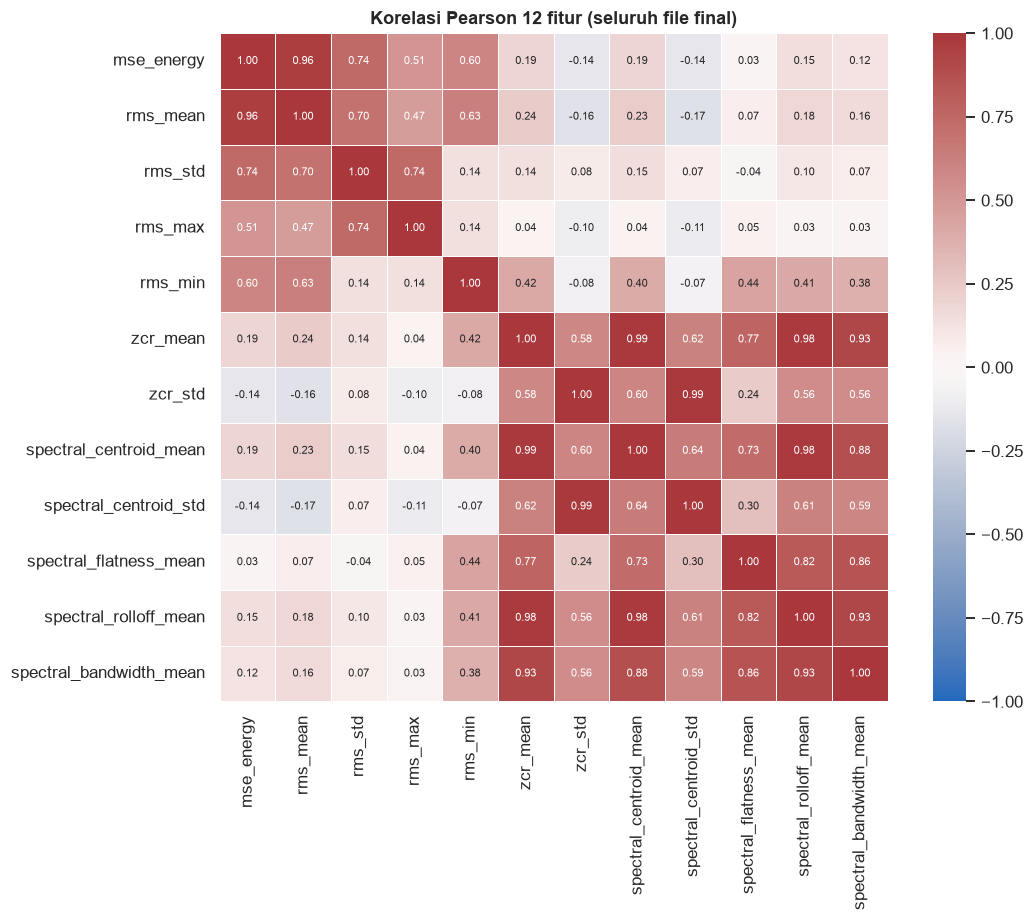

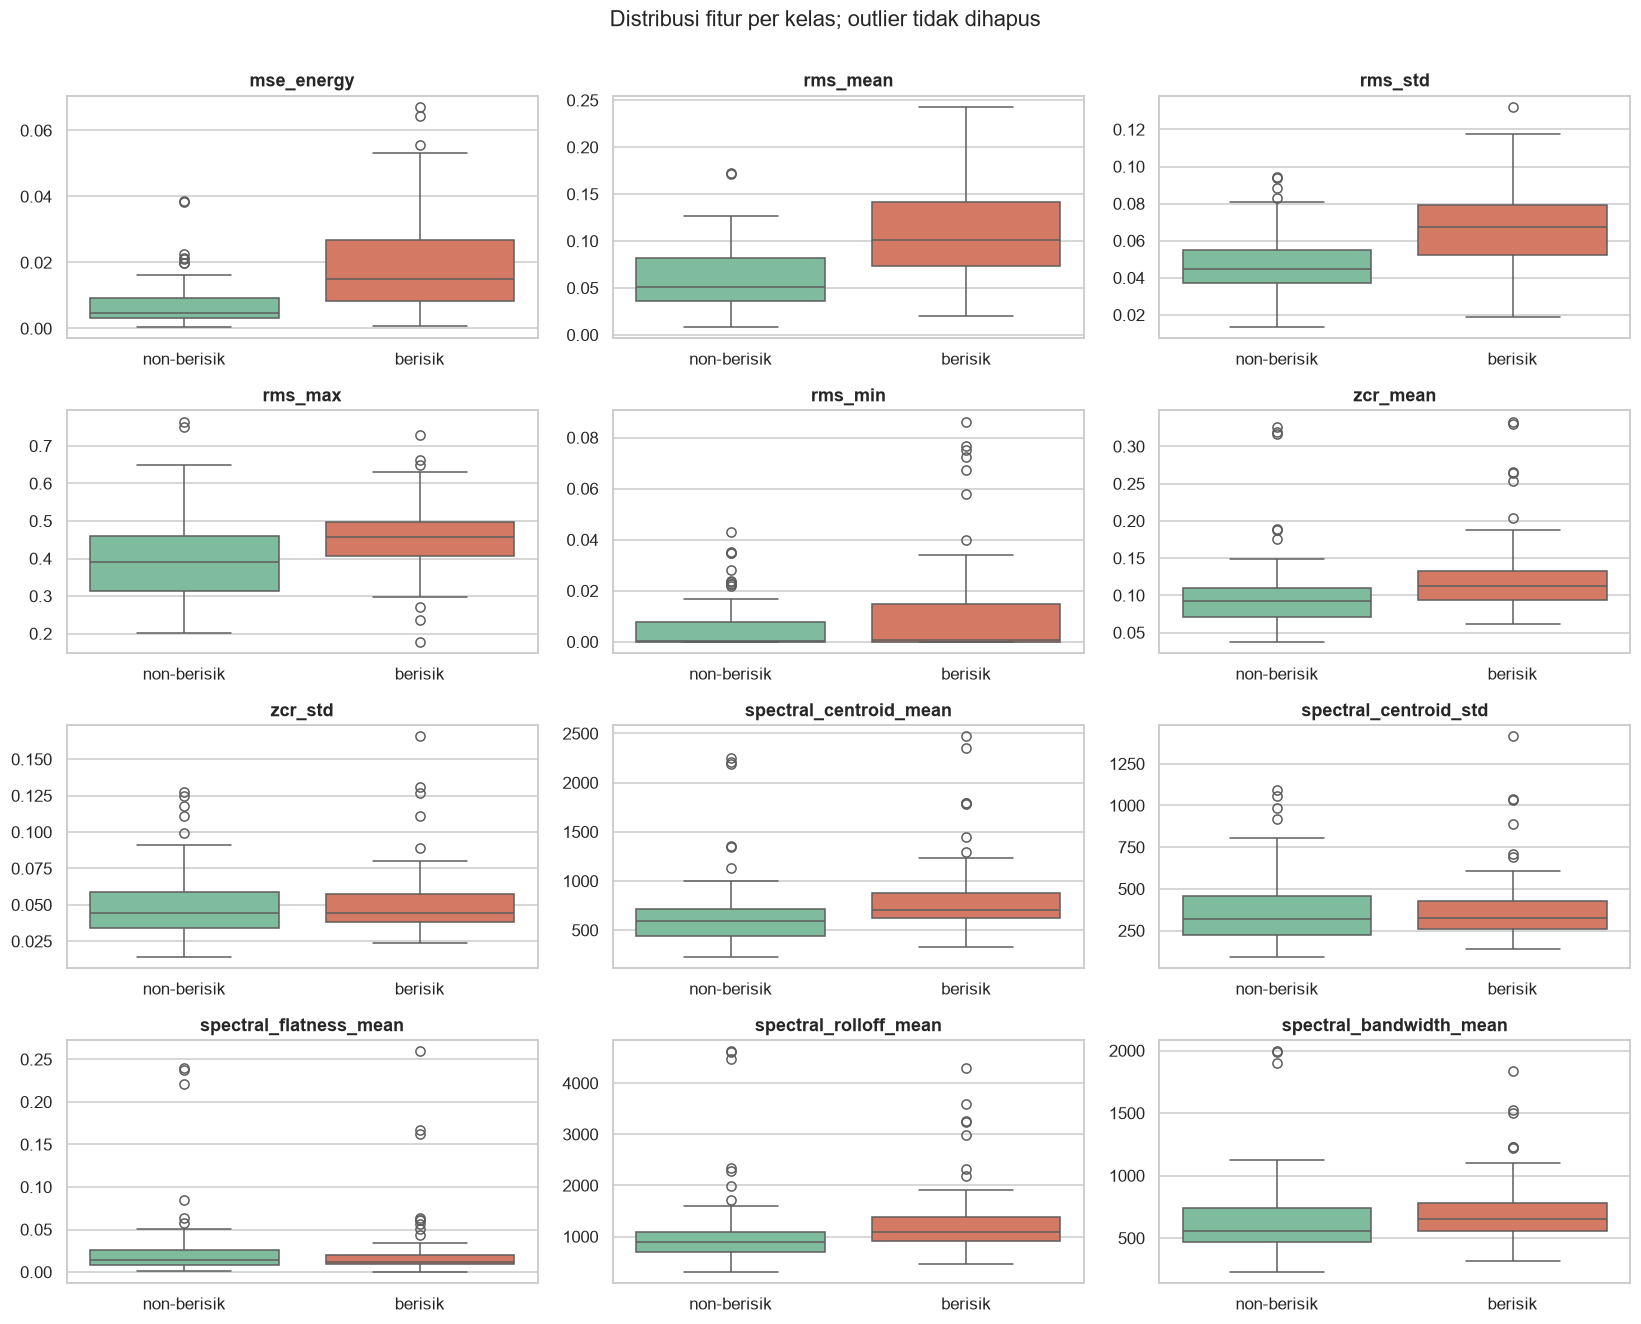

,feature_1,feature_2,pearson_r,abs_r
0,zcr_std,spectral_centroid_std,0.986955,0.986955
1,zcr_mean,spectral_centroid_mean,0.986658,0.986658
2,spectral_centroid_mean,spectral_rolloff_mean,0.983018,0.983018
3,zcr_mean,spectral_rolloff_mean,0.982277,0.982277
4,mse_energy,rms_mean,0.963291,0.963291
5,zcr_mean,spectral_bandwidth_mean,0.929233,0.929233
6,spectral_rolloff_mean,spectral_bandwidth_mean,0.927038,0.927038


label_name,berisik,non-berisik
feature,,
mse_energy,3,7
rms_mean,0,2
rms_std,1,4
rms_max,6,2
rms_min,7,10
zcr_mean,6,6
zcr_std,5,5
spectral_centroid_mean,7,6
spectral_centroid_std,6,4


In [27]:
features["label_name"] = features["label"].map(LABEL_NAME_MAP)
correlation_matrix = features[FEATURE_COLUMNS].corr(method="pearson")

high_corr_rows = []
for left_index, left_feature in enumerate(FEATURE_COLUMNS):
    for right_feature in FEATURE_COLUMNS[left_index + 1 :]:
        value = float(correlation_matrix.loc[left_feature, right_feature])
        if abs(value) > 0.90:
            high_corr_rows.append(
                {
                    "feature_1": left_feature,
                    "feature_2": right_feature,
                    "pearson_r": value,
                    "abs_r": abs(value),
                }
            )
high_corr_pairs = pd.DataFrame(
    high_corr_rows, columns=["feature_1", "feature_2", "pearson_r", "abs_r"]
).sort_values("abs_r", ascending=False, ignore_index=True)

fig, ax = plt.subplots(figsize=(10.5, 8.5))
sns.heatmap(
    correlation_matrix,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    linewidths=0.5,
    square=True,
    ax=ax,
)
ax.set_title("Korelasi Pearson 12 fitur (seluruh file final)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "feature_correlation_heatmap.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, feature in zip(axes.ravel(), FEATURE_COLUMNS):
    sns.boxplot(
        data=features,
        x="label_name",
        y=feature,
        order=LABEL_ORDER,
        hue="label_name",
        palette={"non-berisik": "#74c69d", "berisik": "#e76f51"},
        legend=False,
        dodge=False,
        showfliers=True,
        ax=ax,
    )
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Distribusi fitur per kelas; outlier tidak dihapus", y=1.002)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "feature_boxplots_by_class.png", bbox_inches="tight")
plt.show()

outlier_rows = []
for label_name in LABEL_ORDER:
    label_values = features.loc[features["label_name"] == label_name]
    for feature in FEATURE_COLUMNS:
        values = label_values[feature]
        q1 = float(values.quantile(0.25))
        q3 = float(values.quantile(0.75))
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        outlier_rows.append(
            {
                "label_name": label_name,
                "feature": feature,
                "q1": q1,
                "q3": q3,
                "iqr": iqr,
                "lower_bound": lower,
                "upper_bound": upper,
                "n_outlier_iqr": int(((values < lower) | (values > upper)).sum()),
            }
        )
outlier_counts = pd.DataFrame(outlier_rows)

display(
    high_corr_pairs
    if len(high_corr_pairs)
    else pd.DataFrame({"catatan": ["Tidak ada pasangan fitur dengan |r| > 0,90"]})
)
display(
    outlier_counts.pivot(index="feature", columns="label_name", values="n_outlier_iqr")
    .reindex(FEATURE_COLUMNS)
    .fillna(0)
    .astype(int)
)

correlation_matrix.to_csv(ARTIFACT_DIR / "feature_correlation_pearson.csv")
high_corr_pairs.to_csv(ARTIFACT_DIR / "high_correlation_pairs.csv", index=False)
outlier_counts.to_csv(ARTIFACT_DIR / "outlier_counts_iqr.csv", index=False)


### 4.1 Cohen's d per fitur

#### A. Rumus

Untuk kelas berisik (1) dan non-berisik (0):

\[
d=\frac{\bar{x}_1-\bar{x}_0}{s_p}
\]

\[
s_p=\sqrt{\frac{(n_1-1)s_1^2+(n_0-1)s_0^2}{n_1+n_0-2}}
\]

Jika \(s_p=0\):

- \(d=0\) bila kedua rata-rata sama;
- \(d=+\infty\) atau \(-\infty\) bila rata-rata berbeda, dengan tanda mengikuti \(\bar{x}_1-\bar{x}_0\).

Nilai absolut besar berarti pemisahan rata-rata relatif besar terhadap variasi dalam kelas. Ini bukan ukuran performa model.

#### B. Ilustrasi manual

Kelas 0: \([1,2,3]\), rata-rata 2, varians sampel 1.

Kelas 1: \([4,5,6]\), rata-rata 5, varians sampel 1.

\[
s_p=\sqrt{\frac{2\cdot1+2\cdot1}{4}}=1
\]

\[
d=\frac{5-2}{1}=3
\]

#### C. Implementasi pada data nyata


In [28]:
cohens_rows = []
for feature in FEATURE_COLUMNS:
    group_0 = features.loc[features["label"] == 0, feature].to_numpy(dtype=float)
    group_1 = features.loc[features["label"] == 1, feature].to_numpy(dtype=float)
    n_0, n_1 = len(group_0), len(group_1)
    mean_0, mean_1 = float(np.mean(group_0)), float(np.mean(group_1))
    var_0 = float(np.var(group_0, ddof=1))
    var_1 = float(np.var(group_1, ddof=1))
    pooled_var = ((n_1 - 1) * var_1 + (n_0 - 1) * var_0) / (n_1 + n_0 - 2)
    pooled_sd = float(np.sqrt(pooled_var))
    mean_difference = mean_1 - mean_0

    if pooled_sd == 0:
        if mean_difference == 0:
            cohens_d = 0.0
        else:
            cohens_d = math.copysign(float("inf"), mean_difference)
        note = "s_p=0; d mengikuti aturan eksplisit"
    else:
        cohens_d = mean_difference / pooled_sd
        note = ""

    cohens_rows.append(
        {
            "feature": feature,
            "mean_non_berisik": mean_0,
            "mean_berisik": mean_1,
            "mean_difference": mean_difference,
            "sd_non_berisik": float(np.sqrt(var_0)),
            "sd_berisik": float(np.sqrt(var_1)),
            "pooled_sd": pooled_sd,
            "cohens_d": cohens_d,
            "abs_cohens_d": abs(cohens_d),
            "note": note,
        }
    )

cohens_d_table = (
    pd.DataFrame(cohens_rows)
    .sort_values("abs_cohens_d", ascending=False)
    .reset_index(drop=True)
)
display(cohens_d_table)
cohens_d_table.to_csv(ARTIFACT_DIR / "cohens_d.csv", index=False)


,feature,mean_non_berisik,mean_berisik,mean_difference,sd_non_berisik,sd_berisik,pooled_sd,cohens_d,abs_cohens_d,note
0,rms_mean,0.061527,0.109967,0.048440,0.034589,0.049862,0.042911,1.128845,1.128845,
1,mse_energy,0.007457,0.019639,0.012182,0.007161,0.014837,0.011649,1.045737,1.045737,
2,rms_std,0.046730,0.067747,0.021017,0.017558,0.022458,0.020158,1.042634,1.042634,
3,rms_max,0.394431,0.451960,0.057529,0.115267,0.095183,0.105703,0.544251,0.544251,
4,spectral_centroid_mean,656.282720,825.702495,169.419775,365.153029,365.166034,365.159532,0.463961,0.463961,
5,zcr_mean,0.100535,0.122975,0.022440,0.051673,0.049584,0.050639,0.443137,0.443137,
6,rms_min,0.005753,0.011029,0.005275,0.009732,0.019513,0.015419,0.342149,0.342149,
7,spectral_rolloff_mean,1060.485992,1281.077655,220.591663,768.362521,648.116930,710.787071,0.310348,0.310348,
8,spectral_bandwidth_mean,643.468874,706.140152,62.671277,326.283196,261.466544,295.656454,0.211973,0.211973,
9,spectral_flatness_mean,0.025207,0.021921,-0.003286,0.042078,0.036394,0.039339,-0.083531,0.083531,


### 4.2 Mutual information dan Random Forest importance

Dua metode memberi sudut pandang berbeda:

- **Mutual information** mengukur ketergantungan antara satu fitur dan label, termasuk hubungan non-linear.
- **Random Forest importance** mengukur kontribusi fitur terhadap penurunan impurity di hutan pohon.

Keduanya dihitung pada seluruh data final hanya untuk menyusun kandidat eksploratif. Ini tidak boleh dipakai sebagai seleksi final model.

#### A. Rumus mutual information

\[
I(X;Y)=\sum_{x}\sum_{y}p(x,y)\log\frac{p(x,y)}{p(x)p(y)}
\]

`mutual_info_classif` memakai logaritma natural dan estimator berbasis tetangga untuk fitur kontinu, dengan `random_state=42`.

#### B. Ilustrasi manual

Misalkan \(y=[0,0,1,1]\) dan fitur \(X=[0,0,1,1]\). Fitur tersebut sempurna memisahkan kelas.

\[
p(0,0)=0{,}5,\quad p(1,1)=0{,}5
\]

\[
I(X;Y)=0{,}5\ln\frac{0{,}5}{0{,}5\cdot0{,}5}
+0{,}5\ln\frac{0{,}5}{0{,}5\cdot0{,}5}
=\ln2\approx0{,}693
\]

Fitur yang tidak memberi informasi tentang label memiliki \(I(X;Y)\approx0\).

#### A. Definisi Random Forest importance

Untuk setiap fitur \(j\), kepentingan adalah rata-rata penurunan impurity pada semua node yang memakai fitur tersebut, dibobot jumlah sampel node:

\[
\text{Importance}_j=
\frac{1}{T}\sum_{t=1}^{T}\sum_{\text{node }v\text{ memakai }j}
\frac{N_v}{N}\left[i(v)-\frac{N_{v,L}}{N_v}i(v_L)-\frac{N_{v,R}}{N_v}i(v_R)\right]
\]

dengan \(i(v)\) impurity node, \(N_v\) jumlah sampel node, dan \(T\) jumlah pohon. Nilai dinormalisasi agar total seluruh fitur menjadi 1.

#### B. Ilustrasi

Fitur yang memisahkan kelas hampir sempurna pada banyak pohon akan sering menurunkan impurity besar, sehingga importance-nya tinggi. Fitur acak cenderung jarang terpilih dan rata-rata penurunan impurity-nya rendah. Importance bukan arah pengaruh dan bukan causal effect.

#### C. Implementasi pada data nyata


,feature,mutual_info,mi_rank
0,rms_mean,0.153564,1
1,mse_energy,0.129229,2
2,spectral_rolloff_mean,0.115857,3
3,rms_std,0.081980,4
4,zcr_mean,0.061038,5
5,spectral_centroid_mean,0.046030,6
6,rms_max,0.037210,7
7,spectral_bandwidth_mean,0.035474,8
8,spectral_centroid_std,0.027841,9
9,spectral_flatness_mean,0.000000,10


,feature,rf_importance,rf_rank
0,mse_energy,0.147023,1
1,rms_mean,0.131773,2
2,rms_std,0.117807,3
3,spectral_centroid_mean,0.098990,4
4,spectral_rolloff_mean,0.087503,5
5,zcr_mean,0.079173,6
6,spectral_centroid_std,0.066216,7
7,spectral_flatness_mean,0.062579,8
8,rms_max,0.061654,9
9,spectral_bandwidth_mean,0.055204,10


,feature,mutual_info,rf_importance,mi_rank,rf_rank,mean_rank,cohens_d,abs_cohens_d,selection_method,usage_note
0,rms_mean,0.153564,0.131773,1,2,1.5,1.128845,1.128845,rata-rata peringkat mutual_info_classif dan Ra...,kandidat eksploratif; seleksi final wajib dipe...
1,mse_energy,0.129229,0.147023,2,1,1.5,1.045737,1.045737,rata-rata peringkat mutual_info_classif dan Ra...,kandidat eksploratif; seleksi final wajib dipe...
2,rms_std,0.081980,0.117807,4,3,3.5,1.042634,1.042634,rata-rata peringkat mutual_info_classif dan Ra...,kandidat eksploratif; seleksi final wajib dipe...
3,spectral_rolloff_mean,0.115857,0.087503,3,5,4.0,0.310348,0.310348,rata-rata peringkat mutual_info_classif dan Ra...,kandidat eksploratif; seleksi final wajib dipe...
4,spectral_centroid_mean,0.046030,0.098990,6,4,5.0,0.463961,0.463961,rata-rata peringkat mutual_info_classif dan Ra...,kandidat eksploratif; seleksi final wajib dipe...
5,zcr_mean,0.061038,0.079173,5,6,5.5,0.443137,0.443137,rata-rata peringkat mutual_info_classif dan Ra...,kandidat eksploratif; seleksi final wajib dipe...
6,rms_max,0.037210,0.061654,7,9,8.0,0.544251,0.544251,rata-rata peringkat mutual_info_classif dan Ra...,kandidat eksploratif; seleksi final wajib dipe...
7,spectral_centroid_std,0.027841,0.066216,9,7,8.0,-0.001774,0.001774,rata-rata peringkat mutual_info_classif dan Ra...,kandidat eksploratif; seleksi final wajib dipe...


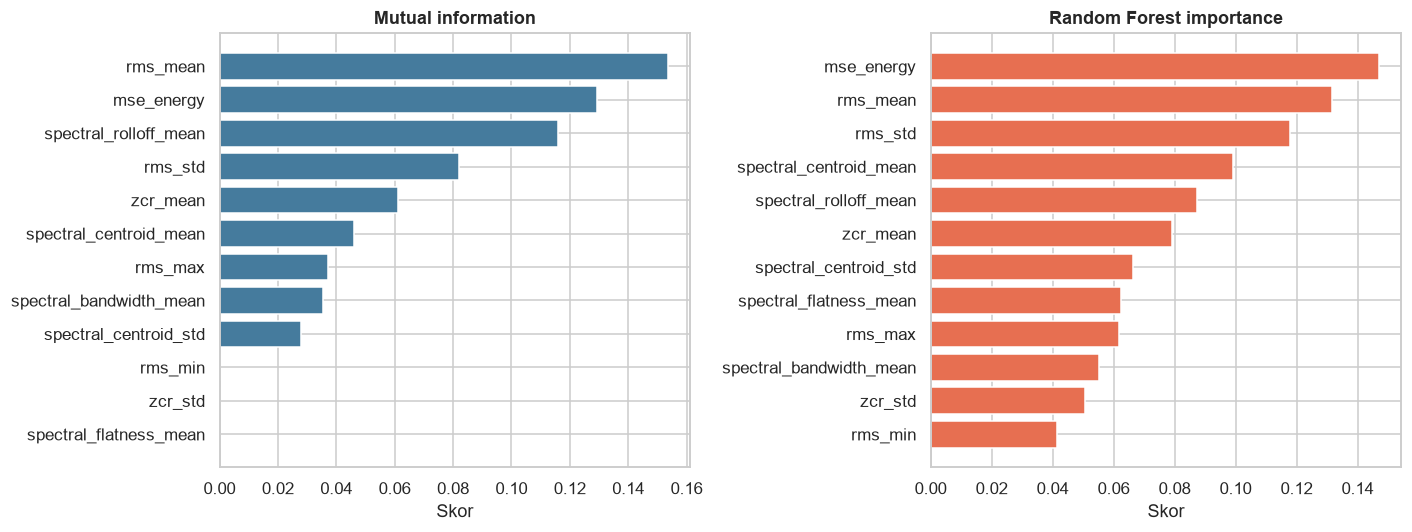

Kandidat top-8: rms_mean, mse_energy, rms_std, spectral_rolloff_mean, spectral_centroid_mean, zcr_mean, rms_max, spectral_centroid_std
File kandidat: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\selected_features.txt


In [29]:
X_features = features[FEATURE_COLUMNS].to_numpy(dtype=float)
y_labels = features["label"].to_numpy(dtype=int)

mi_scores = mutual_info_classif(
    X_features,
    y_labels,
    random_state=RANDOM_STATE,
    n_neighbors=3,
)
rf_model = RandomForestClassifier(
    n_estimators=500,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced",
)
rf_model.fit(X_features, y_labels)
rf_importances = rf_model.feature_importances_

feature_importance = pd.DataFrame(
    {
        "feature": FEATURE_COLUMNS,
        "mutual_info": mi_scores,
        "rf_importance": rf_importances,
    }
)
feature_importance["mi_rank"] = feature_importance["mutual_info"].rank(
    method="min", ascending=False
).astype(int)
feature_importance["rf_rank"] = feature_importance["rf_importance"].rank(
    method="min", ascending=False
).astype(int)
feature_importance["mean_rank"] = (
    feature_importance["mi_rank"] + feature_importance["rf_rank"]
) / 2
feature_importance = feature_importance.merge(
    cohens_d_table[["feature", "cohens_d", "abs_cohens_d"]],
    on="feature",
    validate="one_to_one",
)
feature_importance = feature_importance.sort_values(
    ["mean_rank", "abs_cohens_d", "feature"],
    ascending=[True, False, True],
).reset_index(drop=True)

selected_features = feature_importance.head(8)["feature"].tolist()
selected_features_detail = feature_importance.head(8).copy()
selected_features_detail["selection_method"] = (
    "rata-rata peringkat mutual_info_classif dan RandomForest.feature_importances_"
)
selected_features_detail["usage_note"] = (
    "kandidat eksploratif; seleksi final wajib dipelajari ulang di training fold"
)

display(
    feature_importance[["feature", "mutual_info", "mi_rank"]]
    .sort_values("mi_rank")
    .reset_index(drop=True)
)
display(
    feature_importance[["feature", "rf_importance", "rf_rank"]]
    .sort_values("rf_rank")
    .reset_index(drop=True)
)
display(selected_features_detail)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
mi_order = feature_importance.sort_values("mutual_info", ascending=True)
rf_order = feature_importance.sort_values("rf_importance", ascending=True)
axes[0].barh(mi_order["feature"], mi_order["mutual_info"], color="#457b9d")
axes[0].set_title("Mutual information")
axes[0].set_xlabel("Skor")
axes[1].barh(rf_order["feature"], rf_order["rf_importance"], color="#e76f51")
axes[1].set_title("Random Forest importance")
axes[1].set_xlabel("Skor")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "feature_importance.png", bbox_inches="tight")
plt.show()

feature_importance.to_csv(ARTIFACT_DIR / "feature_importance.csv", index=False)
selected_features_detail.to_csv(ARTIFACT_DIR / "selected_features_detail.csv", index=False)

with open(ARTIFACT_ROOT / "selected_features.txt", "w", encoding="utf-8") as handle:
    handle.write("# Kandidat fitur eksploratif untuk Tahap 04\n")
    handle.write("# Metode: rata-rata peringkat mutual_info_classif dan RandomForest.feature_importances_\n")
    handle.write("# Peringatan: seleksi final dan scaling wajib dipelajari ulang di dalam Pipeline pada training fold.\n")
    handle.write("# mi_rank rf_rank mean_rank cohens_d | feature\n")
    for row in selected_features_detail.itertuples():
        handle.write(
            f"{int(row.mi_rank)} {int(row.rf_rank)} {row.mean_rank:.1f} "
            f"{row.cohens_d:.6f} | {row.feature}\n"
        )

print("Kandidat top-8:", ", ".join(selected_features))
print(f"File kandidat: {ARTIFACT_ROOT / 'selected_features.txt'}")


## 5. Validasi akhir dan serah-terima Tahap 03

Validasi ini memastikan bahwa keluaran Tahap 03 konsisten dan dapat dipakai Tahap 04 tanpa perbaikan diam-diam.

### Checklist

1. Setiap file final memiliki tepat satu baris di `features.csv`.
2. Identitas `file`, `nim`, `take`, dan `label` konsisten antara manifest, WAV, dan fitur.
3. Semua 12 fitur bertipe numerik, tidak mengandung NaN/Inf, dan berada pada rentang logis.
4. Setiap WAV final berdurasi 30 detik, mono 16 kHz, PCM 16-bit, dan tepat 480.000 sampel.
5. Jalur traceability `raw_audio -> data_mp3 -> data_final -> features.csv` lengkap.
6. Distribusi kelas dan NIM final dilaporkan.
7. NIM yang tidak pasti atau tidak memenuhi syarat tidak dimasukkan diam-diam ke split.
8. File yang dikarantina memiliki salinan dan catatan alasan.
9. Split berbasis NIM belum dibuat pada tahap ini.


In [30]:
features_saved = pd.read_csv(ARTIFACT_ROOT / "features.csv")
final_dataset_manifest = transformation_manifest.merge(
    features_saved,
    on=["file", "nim", "take", "label"],
    how="inner",
    validate="one_to_one",
)
final_dataset_manifest = final_dataset_manifest.sort_values(
    ["nim", "label", "take"]
).reset_index(drop=True)

features_by_file_check = features_saved.set_index("file")
audio_checks = []
for row in final_dataset_manifest.itertuples():
    final_path = DATA_FINAL_DIR / row.final_relative_path
    mp3_path = DATA_MP3_DIR / row.mp3_relative_path
    raw_path = RAW_DIR / row.source_relative_path
    y, sr = sf.read(final_path, dtype="float32")
    info = sf.info(final_path)
    audio_checks.append(
        {
            "file": row.file,
            "raw_ada": raw_path.is_file(),
            "mp3_ada": mp3_path.is_file(),
            "final_ada": final_path.is_file(),
            "raw_mp3_hash_sama": row.source_sha256
            == hashlib.sha256(mp3_path.read_bytes()).hexdigest(),
            "final_hash_sama": row.final_sha256
            == hashlib.sha256(final_path.read_bytes()).hexdigest(),
            "sr_16k": sr == SR,
            "mono": info.channels == 1,
            "pcm16": info.subtype == "PCM_16",
            "frames_480000": len(y) == TARGET_SAMPLES,
            "no_nan": int(np.isnan(y).sum()) == 0,
            "no_inf": int(np.isinf(y).sum()) == 0,
            "peak_ok": float(np.max(np.abs(y))) <= 1.00001,
        }
    )
audio_check_frame = pd.DataFrame(audio_checks)

nim_final_check = (
    features_saved.groupby(["nim", "label"]).size().unstack(fill_value=0)
)
for label in [0, 1]:
    if label not in nim_final_check.columns:
        nim_final_check[label] = 0
all_nims_both = bool(
    ((nim_final_check[0] > 0) & (nim_final_check[1] > 0)).all()
)

feature_ranges = {
    "mse_energy": (0, None),
    "rms_mean": (0, None),
    "rms_std": (0, None),
    "rms_max": (0, None),
    "rms_min": (0, None),
    "zcr_mean": (0, 1),
    "zcr_std": (0, None),
    "spectral_centroid_mean": (0, SR / 2),
    "spectral_centroid_std": (0, SR / 2),
    "spectral_flatness_mean": (0, 1),
    "spectral_rolloff_mean": (0, SR / 2),
    "spectral_bandwidth_mean": (0, SR / 2),
}
range_failures = []
for feature, (lower, upper) in feature_ranges.items():
    values = features_saved[feature]
    if lower is not None and (values < lower).any():
        range_failures.append(f"{feature} < {lower}")
    if upper is not None and (values > upper + 1e-9).any():
        range_failures.append(f"{feature} > {upper}")

selected_features_lines = [
    line.split("|")[-1].strip()
    for line in (ARTIFACT_ROOT / "selected_features.txt").read_text(encoding="utf-8").splitlines()
    if line.strip() and not line.startswith("#")
]
selected_features_from_file = selected_features_lines

checks = {
    "file_awal_200": len(manifest) == 200,
    "file_final_176": len(final_dataset_manifest) == 176,
    "file_karantina_24": len(quarantine_manifest) == 24,
    "final_plus_karantina_200": len(final_dataset_manifest) + len(quarantine_manifest)
    == len(manifest),
    "data_mp3_176": len(list(DATA_MP3_DIR.rglob("*.mp3"))) == 176,
    "data_final_176": len(list(DATA_FINAL_DIR.rglob("*.wav"))) == 176,
    "quarantine_24_mp3": len(list(QUARANTINE_DIR.rglob("*.mp3"))) == 24,
    "raw_tetap_200": len(list(RAW_DIR.rglob("*.mp3"))) == 200,
    "features_176": len(features_saved) == 176,
    "features_unik": features_saved["file"].is_unique,
    "fitur_lengkap_12": list(features_saved.columns) == IDENTITY_COLUMNS + FEATURE_COLUMNS,
    "fitur_numerik": all(pd.api.types.is_numeric_dtype(features_saved[column]) for column in FEATURE_COLUMNS),
    "fitur_tanpa_nan": not features_saved[FEATURE_COLUMNS].isna().any().any(),
    "fitur_tanpa_inf": np.isfinite(features_saved[FEATURE_COLUMNS].to_numpy(dtype=float)).all(),
    "rentang_fitur_valid": len(range_failures) == 0,
    "file_identitas_unik": not features_saved.duplicated(["nim", "take", "label"]).any(),
    "kelas_seimbang_88_88": features_saved["label"].value_counts().to_dict() == {0: 88, 1: 88},
    "nim_final_34": features_saved["nim"].nunique() == 34,
    "semua_nim_dua_kelas": all_nims_both,
    "semua_audio_valid": audio_check_frame.drop(columns=["file"]).all().all(),
    "final_hash_unik": final_dataset_manifest["final_sha256"].is_unique,
    "traceability_lengkap": audio_check_frame[
        ["raw_ada", "mp3_ada", "final_ada", "raw_mp3_hash_sama", "final_hash_sama"]
    ].all().all(),
    "rfft_fft_konsisten": fft_rfft_max_abs_diff <= 1e-6,
    "librosa_comparison_5_fitur": len(comparison_summary) == 5,
    "top8_kandidat": len(selected_features_from_file) == 8,
    "top8_semua_ada": set(selected_features_from_file).issubset(set(FEATURE_COLUMNS)),
    "tidak_ada_nim_satu_kelas": not features_saved.groupby("nim")["label"].nunique().eq(1).any(),
    "silent_frames_terdokumentasi": len(silent_frame_audit) == 176,
}
check_table = pd.DataFrame(
    {
        "pemeriksaan": list(checks.keys()),
        "lulus": list(checks.values()),
    }
)
check_table["status"] = np.where(check_table["lulus"], "PASS", "FAIL")

if not all(checks.values()):
    display(check_table)
    raise ValueError("Validasi akhir Tahap 03 gagal.")

uncertain_nims = pd.DataFrame(columns=["nim", "reason", "action"])
excluded_files = quarantine_manifest[
    [
        "relative_path",
        "file",
        "nim",
        "take",
        "label",
        "label_name",
        "selection_reason",
        "duplicate_group_id",
        "duplicate_scope",
        "sha256",
    ]
].copy()

final_dataset_manifest.to_csv(ARTIFACT_DIR / "final_dataset_manifest.csv", index=False)
excluded_files.to_csv(ARTIFACT_DIR / "excluded_files.csv", index=False)
uncertain_nims.to_csv(ARTIFACT_DIR / "uncertain_nims.csv", index=False)
check_table.to_csv(ARTIFACT_DIR / "validation_checks.csv", index=False)
audio_check_frame.to_csv(ARTIFACT_DIR / "audio_validation_detail.csv", index=False)

validation_summary = {
    "status": "PASS",
    "n_raw": int(len(manifest)),
    "n_final": int(len(final_dataset_manifest)),
    "n_quarantine": int(len(quarantine_manifest)),
    "n_features": int(len(features_saved)),
    "n_nim": int(features_saved["nim"].nunique()),
    "class_counts": {str(k): int(v) for k, v in features_saved["label"].value_counts().sort_index().items()},
    "n_final_hashes": int(final_dataset_manifest["final_sha256"].nunique()),
    "n_uncertain_nims": int(len(uncertain_nims)),
    "n_zero_power_frames": int(silent_frame_audit["empty_power_frames"].sum()),
    "n_files_with_zero_power_frames": int((silent_frame_audit["empty_power_frames"] > 0).sum()),
    "selected_features": selected_features_from_file,
    "range_failures": range_failures,
    "fft_rfft_max_abs_diff": float(fft_rfft_max_abs_diff),
    "checks_passed": int(check_table["lulus"].sum()),
    "checks_total": int(len(check_table)),
}
with open(ARTIFACT_DIR / "validation_summary.json", "w", encoding="utf-8") as handle:
    json.dump(validation_summary, handle, ensure_ascii=False, indent=2)

report_lines = [
    "# Laporan Validasi Tahap 03",
    "",
    "Status: **PASS**",
    "",
    "## Angka aktual",
    "",
    f"- File awal: {len(manifest)}",
    f"- File final: {len(final_dataset_manifest)}",
    f"- File karantina: {len(quarantine_manifest)}",
    f"- NIM final: {features_saved['nim'].nunique()}",
    f"- Distribusi kelas: {validation_summary['class_counts']}",
    f"- Baris features.csv: {len(features_saved)}",
    f"- Hash WAV final unik: {final_dataset_manifest['final_sha256'].nunique()}",
    f"- NIM tidak pasti: {len(uncertain_nims)}",
    f"- Frame dengan daya nol: {int(silent_frame_audit['empty_power_frames'].sum())} pada {int((silent_frame_audit['empty_power_frames'] > 0).sum())} file",
    f"- Pemeriksaan lulus: {check_table['lulus'].sum()}/{len(check_table)}",
    "",
    "## Catatan",
    "",
    "- `24-123` tidak memiliki file final karena seluruh file-nya menjadi duplikat non-wakil.",
    "- Frame dengan daya nol adalah hening digital yang nyata; frame tidak dihapus. Centroid, flatness, rolloff, dan bandwidth frame tersebut ditetapkan 0.",
    "- Split berbasis NIM belum dibuat; itu menjadi tanggung jawab Tahap 04.",
    "- Fitur kandidat bersifat eksploratif dan harus dipelajari ulang di dalam Pipeline pada training fold.",
]
with open(ARTIFACT_DIR / "validation_report.md", "w", encoding="utf-8") as handle:
    handle.write("\n".join(report_lines) + "\n")

display(check_table)
print("Validasi akhir Tahap 03: PASS")
print(f"Laporan: {ARTIFACT_DIR / 'validation_report.md'}")


,pemeriksaan,lulus,status
0,file_awal_200,True,PASS
1,file_final_176,True,PASS
2,file_karantina_24,True,PASS
3,final_plus_karantina_200,True,PASS
4,data_mp3_176,True,PASS
5,data_final_176,True,PASS
6,quarantine_24_mp3,True,PASS
7,raw_tetap_200,True,PASS
8,features_176,True,PASS
9,features_unik,True,PASS


Validasi akhir Tahap 03: PASS
Laporan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\03_data_preparation\validation_report.md


In [31]:
from IPython.display import Markdown


def md_table(frame, max_rows=None):
    view = frame if max_rows is None else frame.head(max_rows)
    columns = [str(column) for column in view.columns]
    lines = [
        "| " + " | ".join(columns) + " |",
        "|" + "|".join(["---"] * len(columns)) + "|",
    ]
    for row in view.itertuples(index=False):
        values = []
        for value in row:
            if isinstance(value, (float, np.floating)):
                text = f"{value:.6g}"
            elif isinstance(value, (bool, np.bool_)):
                text = str(bool(value))
            else:
                text = str(value)
            values.append(text.replace("|", "\\|").replace("\n", " "))
        lines.append("| " + " | ".join(values) + " |")
    if len(frame) > len(view):
        lines.append("")
        lines.append(f"*Menampilkan {len(view)} dari {len(frame)} baris.*")
    return "\n".join(lines)


cross_label_excluded = quarantine_manifest.loc[
    quarantine_manifest["selection_reason"] == "duplikat_lintas_label",
    ["file", "nim", "label_name", "duplicate_group_id"],
]
top_correlations = high_corr_pairs.head(5)
top_cohens = cohens_d_table.head(5)
top_mi = feature_importance.sort_values("mutual_info", ascending=False).head(5)
top_rf = feature_importance.sort_values("rf_importance", ascending=False).head(5)

report = f"""# 03 — Data Preparation: Laporan Aktual

## Ringkasan

Dataset final Tahap 03 berisi **{len(final_dataset_manifest)} file**, **{features['nim'].nunique()} NIM**, dan distribusi **{int(features['label'].eq(0).sum())} non-berisik : {int(features['label'].eq(1).sum())} berisik**. Semua NIM final memiliki kedua kelas.

- File awal: {len(manifest)}.
- File final: {len(final_dataset_manifest)}.
- File dikarantina: {len(quarantine_manifest)} (salinan, bukan pemindahan dari `raw_audio/`).
- Grup duplikat same-label: {len(group_choices)}; wakil dipilih: {len(selected_representatives)}.
- NIM yang hilang dari dataset final: {", ".join(search_summary["dropped_nims"]) or "-"}.
- `24-123` tidak punya file final karena seluruh file-nya menjadi duplikat non-wakil.

## Seleksi dan duplikasi

Pemilihan wakil memakai hash SHA-256, bukan kemiripan audio. Duplikat lintas label tidak dipertahankan. Duplikat same-label dipilih satu wakil per hash dengan prioritas: jumlah NIM yang memiliki kedua kelas, jumlah NIM terwakili, lalu menekan NIM satu kelas.

Kombinasi yang dievaluasi: **{n_combinations:,}**. Solusi terpilih memiliki **{search_summary["best_both_class_nims"]} NIM dua kelas**, **{search_summary["best_one_class_nims"]} NIM satu kelas**, dan **{search_summary["best_represented_nims"]} NIM terwakili**.

File duplikat lintas label yang dikarantina:

{md_table(cross_label_excluded) if len(cross_label_excluded) else "Tidak ada."}

## Audio final

- `data_mp3/`: {len(staging_manifest)} file, seluruhnya salinan byte-identik karena sumber sudah MP3.
- `data_final/`: {len(transformation_manifest)} WAV.
- Format: WAV PCM_16, mono, {SR} Hz.
- Panjang: tepat {TARGET_SAMPLES} sampel = {TARGET_DURATION_S:.0f} detik.
- Aksi durasi: {transformation_manifest['duration_action'].value_counts().to_dict()}.
- Peak sebelum normalisasi: min {transformation_manifest['peak_before_norm'].min():.5f}, median {transformation_manifest['peak_before_norm'].median():.5f}, max {transformation_manifest['peak_before_norm'].max():.5f}.
- Peak WAV setelah PCM16: min {transformation_manifest['peak_pcm16'].min():.5f}, max {transformation_manifest['peak_pcm16'].max():.5f}.
- Semua WAV memiliki hash unik: {final_dataset_manifest['final_sha256'].is_unique}.

Kontrak preprocessing lengkap tersimpan di `artifacts/03_data_preparation/preprocessing_contract.json`.

## Fitur

- Jumlah fitur: 12.
- Jumlah frame per file: {example_frames.shape[0]} (frame 400 sampel, hop 160, tanpa `center=True`).
- Window: Hann simetris 400 sampel.
- FFT: 512 titik; 257 bin rFFT; resolusi {FREQS[1] - FREQS[0]:.2f} Hz.
- Pemeriksaan rFFT vs FFT penuh, selisih daya maksimum: {fft_rfft_max_abs_diff:.3e}.
- Frame dengan daya nol: {int(silent_frame_audit['empty_power_frames'].sum())} pada {int((silent_frame_audit['empty_power_frames'] > 0).sum())} file. Hening tidak dihapus; fitur spektral frame tersebut ditetapkan 0.
- `features.csv`: {len(features)} baris, tanpa NaN/Inf, seluruh rentang fitur valid.

### Korelasi tinggi (|r| > 0,90)

{md_table(top_correlations) if len(top_correlations) else "Tidak ada."}

Korelasi tinggi ditandai, tetapi tidak ada fitur yang dihapus otomatis.

### Cohen's d teratas

{md_table(top_cohens[['feature', 'mean_non_berisik', 'mean_berisik', 'pooled_sd', 'cohens_d']])}

### Mutual information teratas

{md_table(top_mi[['feature', 'mutual_info', 'mi_rank']])}

### Random Forest importance teratas

{md_table(top_rf[['feature', 'rf_importance', 'rf_rank']])}

### Kandidat top-8

Kandidat dipilih dari rata-rata peringkat mutual information dan Random Forest importance:

{chr(10).join(f"- {feature}" for feature in selected_features_from_file)}

Kandidat ini **eksploratif**. Seleksi final dan scaling wajib dipelajari ulang di dalam `Pipeline` pada training fold Tahap 04. Tidak ada PCA.

## Pengecekan librosa

{md_table(comparison_summary[['feature', 'manual_mean', 'librosa_mean', 'mean_abs_difference', 'pearson_r', 'note']])}

Perbedaan centroid, bandwidth, rolloff, dan flatness sebagian berasal dari definisi manual berbasis daya \\(P=|S|^2\\) versus librosa berbasis magnitudo. ZCR dapat berbeda karena konvensi tepi frame.

## Validasi akhir

Semua pemeriksaan lulus: **{int(check_table['lulus'].sum())}/{len(check_table)}**.

{md_table(check_table[['pemeriksaan', 'status']])}

Traceability `raw_audio -> data_mp3 -> data_final -> features.csv` lengkap untuk {len(final_dataset_manifest)} file.

## Batasan

- Split train/test belum dibuat pada tahap ini.
- Tidak ada training model final atau GridSearchCV; Random Forest hanya dipakai untuk importance eksploratif.
- Dataset final hanya berisi file yang bukan duplikat non-wakil dan bukan duplikat lintas label.
- File karantina tetap tersedia untuk audit, bukan untuk modeling.
- `raw_audio/` tidak diubah.

## Artefak

- `artifacts/features.csv`
- `artifacts/selected_features.txt`
- `artifacts/03_data_preparation/final_dataset_manifest.csv`
- `artifacts/03_data_preparation/validation_report.md`
- `artifacts/03_data_preparation/validation_summary.json`
- `artifacts/03_data_preparation/librosa_comparison_summary.csv`
- `quarantine/03_data_preparation/CATATAN_KARANTINA.csv`

## Kesimpulan dan keputusan untuk Tahap 04

1. **Jumlah aktual:** 176 file final, 24 file karantina, 34 NIM, kelas 88 non-berisik : 88 berisik, semua NIM berdua kelas, `24-123` gugur.
2. **Duplikasi selesai:** 1 grup lintas label (DUP04) dikarantina seluruhnya; 17 grup same-label memilih satu wakil; tidak ada data kembar yang lolos ke modeling.
3. **Format seragam:** semua final adalah WAV PCM_16 mono 16000 Hz tepat 480000 sampel dengan peak normalization; `data_mp3/` hanya salinan byte-identik.
4. **Fitur:** 12 fitur numerik tervalidasi untuk 176 file; tidak ada NaN/Inf; pemeriksaan rFFT vs FFT penuh konsisten.
5. **Kandidat fitur:** 8 kandidat eksploratif disimpan di `artifacts/selected_features.txt`; wajib dipelajari ulang di training fold, bukan dipakai sebagai keputusan final.
6. **Belum dilakukan:** split berbasis NIM, training model, GridSearchCV, dan evaluasi hold-out.

**Data Preparation selesai dan tervalidasi. Model belum dilatih.**
"""

(ARTIFACT_DIR / "data_preparation_report.md").write_text(report, encoding="utf-8")

data_preparation_summary = {
    "status": "PASS",
    "n_raw": int(len(manifest)),
    "n_final": int(len(final_dataset_manifest)),
    "n_quarantine": int(len(quarantine_manifest)),
    "n_nim_final": int(features["nim"].nunique()),
    "class_counts": {str(k): int(v) for k, v in features["label"].value_counts().sort_index().items()},
    "n_features": len(FEATURE_COLUMNS),
    "n_frames_per_file": int(example_frames.shape[0]),
    "n_zero_power_frames": int(silent_frame_audit["empty_power_frames"].sum()),
    "n_files_with_zero_power_frames": int((silent_frame_audit["empty_power_frames"] > 0).sum()),
    "sample_rate": SR,
    "target_samples": TARGET_SAMPLES,
    "duration_actions": {str(k): int(v) for k, v in transformation_manifest["duration_action"].value_counts().items()},
    "top8_candidates": selected_features_from_file,
    "dropped_nims": search_summary["dropped_nims"],
    "fft_rfft_max_abs_diff": float(fft_rfft_max_abs_diff),
}
with open(ARTIFACT_DIR / "data_preparation_summary.json", "w", encoding="utf-8") as handle:
    json.dump(data_preparation_summary, handle, ensure_ascii=False, indent=2)

print(f"Laporan tahap: {ARTIFACT_DIR / 'data_preparation_report.md'}")
display(Markdown(report))


Laporan tahap: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\03_data_preparation\data_preparation_report.md


# 03 — Data Preparation: Laporan Aktual

## Ringkasan

Dataset final Tahap 03 berisi **176 file**, **34 NIM**, dan distribusi **88 non-berisik : 88 berisik**. Semua NIM final memiliki kedua kelas.

- File awal: 200.
- File final: 176.
- File dikarantina: 24 (salinan, bukan pemindahan dari `raw_audio/`).
- Grup duplikat same-label: 17; wakil dipilih: 17.
- NIM yang hilang dari dataset final: 24-123.
- `24-123` tidak punya file final karena seluruh file-nya menjadi duplikat non-wakil.

## Seleksi dan duplikasi

Pemilihan wakil memakai hash SHA-256, bukan kemiripan audio. Duplikat lintas label tidak dipertahankan. Duplikat same-label dipilih satu wakil per hash dengan prioritas: jumlah NIM yang memiliki kedua kelas, jumlah NIM terwakili, lalu menekan NIM satu kelas.

Kombinasi yang dievaluasi: **995,328**. Solusi terpilih memiliki **34 NIM dua kelas**, **0 NIM satu kelas**, dan **34 NIM terwakili**.

File duplikat lintas label yang dikarantina:

| file | nim | label_name | duplicate_group_id |
|---|---|---|---|
| 24-034_berisik_1.mp3 | 24-034 | berisik | DUP04 |
| 24-034_non-berisik_1.mp3 | 24-034 | non-berisik | DUP04 |

## Audio final

- `data_mp3/`: 176 file, seluruhnya salinan byte-identik karena sumber sudah MP3.
- `data_final/`: 176 WAV.
- Format: WAV PCM_16, mono, 16000 Hz.
- Panjang: tepat 480000 sampel = 30 detik.
- Aksi durasi: {'none': 176}.
- Peak sebelum normalisasi: min 0.02124, median 0.58248, max 1.34783.
- Peak WAV setelah PCM16: min 0.99997, max 1.00000.
- Semua WAV memiliki hash unik: True.

Kontrak preprocessing lengkap tersimpan di `artifacts/03_data_preparation/preprocessing_contract.json`.

## Fitur

- Jumlah fitur: 12.
- Jumlah frame per file: 2998 (frame 400 sampel, hop 160, tanpa `center=True`).
- Window: Hann simetris 400 sampel.
- FFT: 512 titik; 257 bin rFFT; resolusi 31.25 Hz.
- Pemeriksaan rFFT vs FFT penuh, selisih daya maksimum: 1.819e-12.
- Frame dengan daya nol: 1677 pada 52 file. Hening tidak dihapus; fitur spektral frame tersebut ditetapkan 0.
- `features.csv`: 176 baris, tanpa NaN/Inf, seluruh rentang fitur valid.

### Korelasi tinggi (|r| > 0,90)

| feature_1 | feature_2 | pearson_r | abs_r |
|---|---|---|---|
| zcr_std | spectral_centroid_std | 0.986955 | 0.986955 |
| zcr_mean | spectral_centroid_mean | 0.986658 | 0.986658 |
| spectral_centroid_mean | spectral_rolloff_mean | 0.983018 | 0.983018 |
| zcr_mean | spectral_rolloff_mean | 0.982277 | 0.982277 |
| mse_energy | rms_mean | 0.963291 | 0.963291 |

Korelasi tinggi ditandai, tetapi tidak ada fitur yang dihapus otomatis.

### Cohen's d teratas

| feature | mean_non_berisik | mean_berisik | pooled_sd | cohens_d |
|---|---|---|---|---|
| rms_mean | 0.0615274 | 0.109967 | 0.0429107 | 1.12885 |
| mse_energy | 0.00745723 | 0.0196392 | 0.0116492 | 1.04574 |
| rms_std | 0.0467297 | 0.0677468 | 0.0201577 | 1.04263 |
| rms_max | 0.394431 | 0.45196 | 0.105703 | 0.544251 |
| spectral_centroid_mean | 656.283 | 825.702 | 365.16 | 0.463961 |

### Mutual information teratas

| feature | mutual_info | mi_rank |
|---|---|---|
| rms_mean | 0.153564 | 1 |
| mse_energy | 0.129229 | 2 |
| spectral_rolloff_mean | 0.115857 | 3 |
| rms_std | 0.0819795 | 4 |
| zcr_mean | 0.061038 | 5 |

### Random Forest importance teratas

| feature | rf_importance | rf_rank |
|---|---|---|
| mse_energy | 0.147023 | 1 |
| rms_mean | 0.131773 | 2 |
| rms_std | 0.117807 | 3 |
| spectral_centroid_mean | 0.0989899 | 4 |
| spectral_rolloff_mean | 0.0875027 | 5 |

### Kandidat top-8

Kandidat dipilih dari rata-rata peringkat mutual information dan Random Forest importance:

- rms_mean
- mse_energy
- rms_std
- spectral_rolloff_mean
- spectral_centroid_mean
- zcr_mean
- rms_max
- spectral_centroid_std

Kandidat ini **eksploratif**. Seleksi final dan scaling wajib dipelajari ulang di dalam `Pipeline` pada training fold Tahap 04. Tidak ada PCA.

## Pengecekan librosa

| feature | manual_mean | librosa_mean | mean_abs_difference | pearson_r | note |
|---|---|---|---|---|---|
| spectral_centroid_mean | 740.993 | 1467.94 | 726.948 | 0.894871 | manual=P, librosa=magnitudo |
| spectral_bandwidth_mean | 674.805 | 1478.61 | 803.804 | 0.78573 | manual=P, librosa=magnitudo |
| spectral_rolloff_mean | 1170.78 | 2904.78 | 1734 | 0.793539 | manual=P, librosa=magnitudo |
| spectral_flatness_mean | 0.0235638 | 0.0268005 | 0.00323671 | 0.776373 | manual=P, librosa=magnitudo |
| zcr_mean | 0.111755 | 0.11296 | 0.00133051 | 0.996371 | konvensi zero-crossing dapat berbeda di tepi frame |

Perbedaan centroid, bandwidth, rolloff, dan flatness sebagian berasal dari definisi manual berbasis daya \(P=|S|^2\) versus librosa berbasis magnitudo. ZCR dapat berbeda karena konvensi tepi frame.

## Validasi akhir

Semua pemeriksaan lulus: **28/28**.

| pemeriksaan | status |
|---|---|
| file_awal_200 | PASS |
| file_final_176 | PASS |
| file_karantina_24 | PASS |
| final_plus_karantina_200 | PASS |
| data_mp3_176 | PASS |
| data_final_176 | PASS |
| quarantine_24_mp3 | PASS |
| raw_tetap_200 | PASS |
| features_176 | PASS |
| features_unik | PASS |
| fitur_lengkap_12 | PASS |
| fitur_numerik | PASS |
| fitur_tanpa_nan | PASS |
| fitur_tanpa_inf | PASS |
| rentang_fitur_valid | PASS |
| file_identitas_unik | PASS |
| kelas_seimbang_88_88 | PASS |
| nim_final_34 | PASS |
| semua_nim_dua_kelas | PASS |
| semua_audio_valid | PASS |
| final_hash_unik | PASS |
| traceability_lengkap | PASS |
| rfft_fft_konsisten | PASS |
| librosa_comparison_5_fitur | PASS |
| top8_kandidat | PASS |
| top8_semua_ada | PASS |
| tidak_ada_nim_satu_kelas | PASS |
| silent_frames_terdokumentasi | PASS |

Traceability `raw_audio -> data_mp3 -> data_final -> features.csv` lengkap untuk 176 file.

## Batasan

- Split train/test belum dibuat pada tahap ini.
- Tidak ada training model final atau GridSearchCV; Random Forest hanya dipakai untuk importance eksploratif.
- Dataset final hanya berisi file yang bukan duplikat non-wakil dan bukan duplikat lintas label.
- File karantina tetap tersedia untuk audit, bukan untuk modeling.
- `raw_audio/` tidak diubah.

## Artefak

- `artifacts/features.csv`
- `artifacts/selected_features.txt`
- `artifacts/03_data_preparation/final_dataset_manifest.csv`
- `artifacts/03_data_preparation/validation_report.md`
- `artifacts/03_data_preparation/validation_summary.json`
- `artifacts/03_data_preparation/librosa_comparison_summary.csv`
- `quarantine/03_data_preparation/CATATAN_KARANTINA.csv`

## Kesimpulan dan keputusan untuk Tahap 04

1. **Jumlah aktual:** 176 file final, 24 file karantina, 34 NIM, kelas 88 non-berisik : 88 berisik, semua NIM berdua kelas, `24-123` gugur.
2. **Duplikasi selesai:** 1 grup lintas label (DUP04) dikarantina seluruhnya; 17 grup same-label memilih satu wakil; tidak ada data kembar yang lolos ke modeling.
3. **Format seragam:** semua final adalah WAV PCM_16 mono 16000 Hz tepat 480000 sampel dengan peak normalization; `data_mp3/` hanya salinan byte-identik.
4. **Fitur:** 12 fitur numerik tervalidasi untuk 176 file; tidak ada NaN/Inf; pemeriksaan rFFT vs FFT penuh konsisten.
5. **Kandidat fitur:** 8 kandidat eksploratif disimpan di `artifacts/selected_features.txt`; wajib dipelajari ulang di training fold, bukan dipakai sebagai keputusan final.
6. **Belum dilakukan:** split berbasis NIM, training model, GridSearchCV, dan evaluasi hold-out.

**Data Preparation selesai dan tervalidasi. Model belum dilatih.**


## Kesimpulan dan keputusan untuk tahap 04

1. **Jumlah aktual:** 176 file final dari 200 file mentah, 24 file dikarantina dengan salinan dan alasan. Dataset final: **34 NIM**, **88 non-berisik : 88 berisik**, semua NIM memiliki kedua kelas. NIM `24-123` gugur karena seluruh file-nya menjadi duplikat non-wakil.
2. **Duplikasi selesai:** dari 18 grup duplikat eksak Tahap 02, 1 grup lintas label (DUP04) dikarantina seluruhnya dan 17 grup same-label memilih satu wakil. Kombinasi yang dievaluasi **995.328**; solusi terpilih memberi 34 NIM dua kelas dan 0 NIM satu kelas.
3. **Format seragam:** `data_mp3/` adalah salinan byte-identik 176 MP3 (bukan transcode ganda), `data_final/` adalah 176 WAV PCM_16 mono 16000 Hz tepat 480.000 sampel dengan peak normalization. `raw_audio/` tidak diubah: 200 file dan seluruh SHA-256 cocok manifest Tahap 02.
4. **Fitur:** 12 fitur terekstrak manual (frame 400, hop 160, Hann simetris, N_FFT 512, 2.998 frame per file). `features.csv` berisi 176 baris tanpa NaN/Inf dan seluruh rentang fitur valid. Pemeriksaan rFFT vs FFT penuh selisih maksimum 1.819e-12.
5. **Frame hening:** 1.677 frame daya-nol pada 52 file. Frame tidak dihapus; centroid, flatness, rolloff, dan bandwidth frame tersebut ditetapkan 0. Hening adalah bagian data, bukan missing value.
6. **Validasi:** 28/28 pemeriksaan **PASS**; traceability `raw_audio -> data_mp3 -> data_final -> features.csv` lengkap dan 176 hash WAV unik.
7. **Kandidat fitur:** 8 kandidat eksploratif (`rms_mean`, `mse_energy`, `rms_std`, `spectral_rolloff_mean`, `spectral_centroid_mean`, `zcr_mean`, `rms_max`, `spectral_centroid_std`). Angka-angka pemilihan fitur bersifat eksploratif dan wajib dipelajari ulang di dalam training fold.
8. **Rencana 04:** split berbasis NIM (hold-out per NIM dan/atau GroupKFold/StratifiedGroupKFold), satu `Pipeline` berisi seleksi fitur, scaling, dan model agar tidak ada kebocoran preprocessing, lalu `GridSearchCV`, evaluasi hold-out per NIM, dan penyimpanan `best_model.joblib`. Tidak ada PCA.

**Data Preparation selesai dan tervalidasi. Model belum dilatih.**
